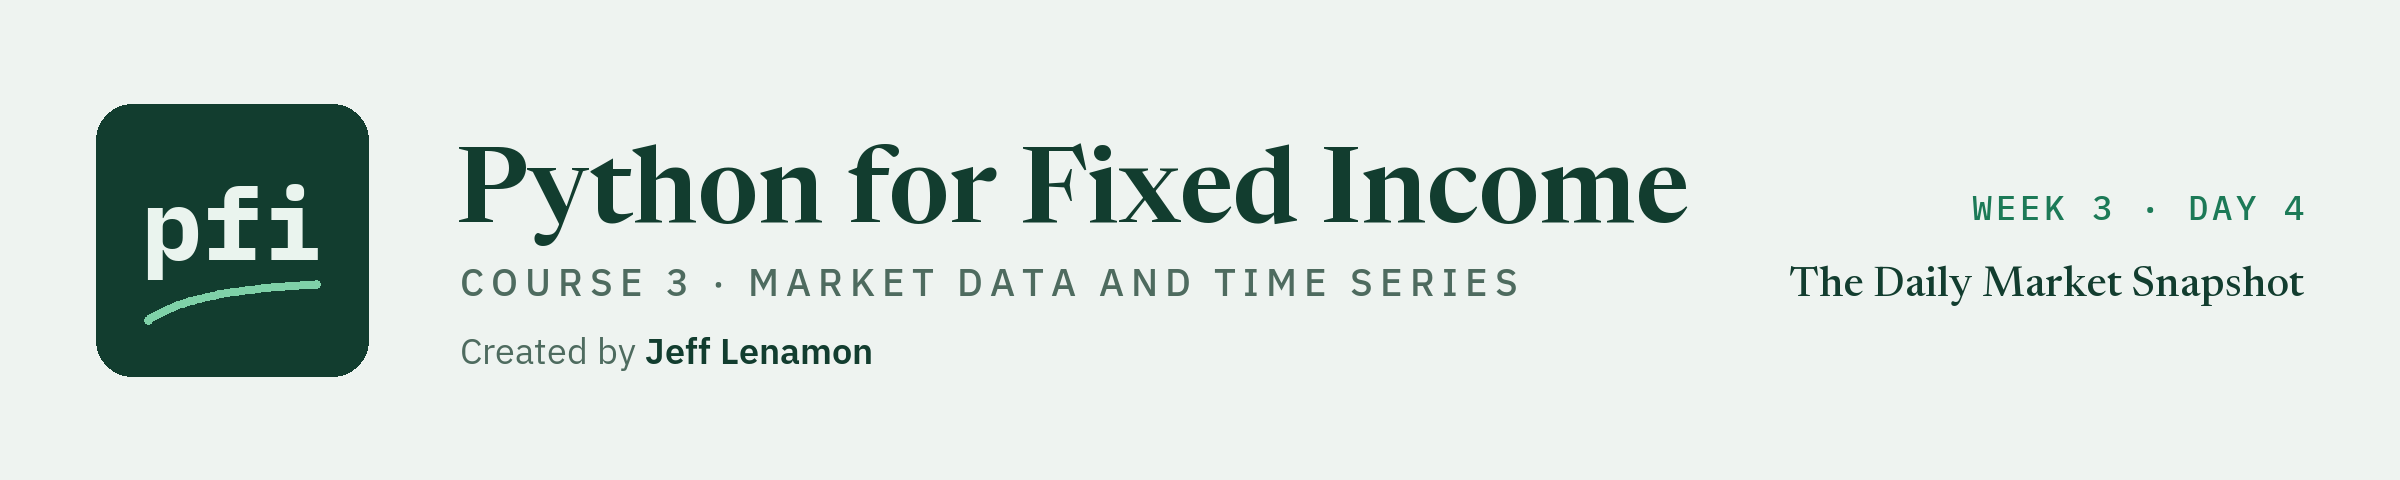

# The Daily Market Snapshot

Week 3, Day 4. Put the course's measures on one page for one date: levels, changes, where each series sits in its own year, the shape of the curve, and the book's mechanical sensitivity, written as HTML and as Excel by a script that runs again on any date.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course3_market_data/week3/day4/14_the_daily_market_snapshot.ipynb)

Many desks start the day with a one-page market snapshot: where the curve and spreads closed, how they moved, and where they sit in their own recent history. Today you build one, from the pieces of the last thirteen days, for Friday 2026-10-02, the last date in the course's Treasury file. Then you run the same code, unchanged, for Wednesday 2026-09-30.

Yesterday you reviewed an assistant's code by testing it against its docstring. Today's code is your own, and the same habit guards it: four new tests, one of which is written for exactly the bug a snapshot is most likely to have.

Today you will:

1. Decide what goes on a one-page snapshot, and hold it to one rule: it describes.
2. Write `snapshot_tables`, docstring first: levels, the curve on two days, slopes and flies, and the book.
3. Read the book section: the synthetic September book's DV01 by sector and rating bucket, and the mechanical change in its value from the day's real curve change, a what-if.
4. Draw the two charts.
5. Write the snapshot as one HTML file and one Excel workbook, and read both back.
6. Turn it into `snapshot.py`, run it from the notebook for two dates, and see how Windows Task Scheduler would run it every day.

**No key today.** The snapshot is built from the frozen files, so it reruns to the same numbers on any machine. Nothing in this notebook touches the network.

Q. Set up today's work folder. The test file reads several data files, so all of them are copied in.

## Before you start: install the libraries

Run this cell first. It checks that every library this course pins in its `requirements.txt` is installed and installs only what is missing, so it finishes in a second on a machine set up from the repo's `requirements.txt` and does the installing for you in Google Colab. If it installs anything in Colab, restart the session (Runtime, Restart session) and run the notebook again from the top.

In [1]:
# install what this notebook needs: the course's pinned libraries, only those not already present
import importlib.util
import subprocess
import sys

# import name: the pinned package, from course3_market_data/requirements.txt
NEEDED = {
    "ipykernel": "ipykernel==7.4.0",
    "jinja2": "jinja2==3.1.6",
    "matplotlib": "matplotlib==3.11.2",
    "numpy": "numpy==2.5.3",
    "openpyxl": "openpyxl==3.1.5",
    "pandas": "pandas==3.0.6",
    "pytest": "pytest==9.1.1",
    "dotenv": "python-dotenv==1.2.4",
    "requests": "requests==2.34.2",
}

# a package is present when Python can find its module; the version is left as the machine has it
missing = [pin for module, pin in NEEDED.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing], check=True)
    print(f"{len(NEEDED)} packages checked, {len(missing)} installed: restart the session and run again from the top")
else:
    print(f"{len(NEEDED)} packages checked, all present")

9 packages checked, all present


In [2]:
# today's setup: modules, the course data, a fresh work folder, and the constants the live cells use
import importlib
import os
import shutil
import subprocess
import sys
import tempfile
import urllib.request
from pathlib import Path

import pandas as pd

# the course's chart style, set once here so every chart in the notebook looks the same
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (9, 5),          # width and height of a chart, in inches
    "figure.dpi": 110,                 # sharpness on screen
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    # the course greens, then a grey, for the first four lines or bars of a chart
    "axes.prop_cycle": plt.cycler(color=["#123d2f", "#1c7a57", "#7fd1a8", "#8c8c8c"]),
    "axes.grid": True,                 # light gridlines, as in an Excel chart
    "grid.color": "#dddddd",
    "axes.spines.top": False,          # no box line above or to the right of the plot
    "axes.spines.right": False,
})

# three packages a Colab runtime or a new environment may lack: stop with the line that installs the missing one
for module_name, install_name in [("pytest", "pytest"), ("requests", "requests"), ("dotenv", "python-dotenv")]:
    try:
        importlib.import_module(module_name)
    except ImportError:
        raise RuntimeError(f"{install_name} is not installed. Run  !pip install {install_name}  in a new cell, "
                           "then run this cell again.") from None
import pytest
import requests

# remember the notebook's own folder, so that running this cell again starts from the same place
if "notebook_folder" not in globals():
    notebook_folder = Path.cwd()

# 1. find the course data before moving: the repo's data folder on your machine, GitHub in Colab
RAW_DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"
local_data = (notebook_folder / ".." / ".." / ".." / "data").resolve()
on_github = not (local_data / "treasury_par_yields.csv").exists()
data_folder = RAW_DATA if on_github else str(local_data) + os.sep

# 2. your own key file: in your my_bondmath folder, outside every repository. Its path is never printed.
ENV_FILE = Path.home() / "projects" / "my_bondmath" / ".env"

# 3. the two constants of the live cells
NO_KEY_MESSAGE = "Live cell skipped: no FRED key was found. Every other cell runs without one."
# ICE BofA and Moody's values stay off the screen unless you set this to True, on your own machine only
SHOW_LICENSED_VALUES = False

# 4. a fresh work folder for today, in the system temp folder, outside the course repo
work = Path(tempfile.mkdtemp(prefix="pfi_course3_14_"))
os.chdir(work)

# 5. copy today's data files into the work folder
DATA_FILES = ["treasury_par_yields.csv", "course3_synthetic_spreads.csv", "holdings.csv", "course3_fred_format_dgs10.json", "course3_fred_format_dgs2.json", "course3_excel_reference.csv", "ratings.csv", "trade_blotter.csv"]
for name in DATA_FILES:
    if on_github:
        urllib.request.urlretrieve(RAW_DATA + name, work / name)
    else:
        shutil.copy(local_data / name, work / name)

# print the folder's name only: its full path would show your user name
print(f"Work folder: {work.name}, in your temp folder")
print(f"Data files from {'GitHub' if on_github else 'the data folder of the course repo'}: {', '.join(DATA_FILES) or 'none'}")
print(f"pytest {pytest.__version__}, requests {requests.__version__}")

Work folder: pfi_course3_14_t8dfjvks, in your temp folder
Data files from the data folder of the course repo: treasury_par_yields.csv, course3_synthetic_spreads.csv, holdings.csv, course3_fred_format_dgs10.json, course3_fred_format_dgs2.json, course3_excel_reference.csv, ratings.csv, trade_blotter.csv
pytest 9.1.1, requests 2.34.2


Q. Write `bondmath.py`, the reference copy of the module you finished in Course 2.

It is written into the work folder so that every notebook runs, in Colab too, whether or not you took Course 2. To use your own copy instead, run this line in a new cell after the next one:

```python
shutil.copy(Path.home() / "projects" / "my_bondmath" / "bondmath.py", work)
```

The saved outputs of this notebook always come from the reference copy.

In [3]:
%%writefile bondmath.py
"""bondmath: bond math for fixed-rate bullet bonds, checked against Excel.

Written day by day in Python for Fixed Income, Course 2: Bond Math.

Units, the same in every function:
- coupon_pct and yield_pct are annual rates in percent: 7.0 means 7 percent. Excel takes decimals (0.07).
- Prices and accrued interest are per 100 of face.
- Durations are in years, convexity in years squared, spreads in basis points.
- frequency is the number of coupons (or compounding periods) a year: 1, 2, or 4.
- basis is the day count: "30/360" (Excel basis 0) or "ACT/ACT" (Excel basis 1).
- Dates are datetime.date values.
"""
import calendar  # month lengths, used from week 2
from datetime import date  # calendar dates, used from week 2


def future_value(amount: float, rate_pct: float, years: float, frequency: int = 2) -> float:
    """Grow an amount at an annual rate compounded `frequency` times a year.

    Units: amount in dollars (or per 100 of face), rate_pct in percent, years in years.
    Convention: periodic compounding, amount x (1 + rate / frequency) ** (frequency x years).
    Excel: =FV(rate_pct/100/frequency, frequency*years, 0, -amount)
    """
    # stop on a frequency the course does not use
    if frequency not in (1, 2, 4):
        raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    # the rate for one period, as a decimal
    period_rate = rate_pct / 100 / frequency
    # the number of compounding periods
    periods = frequency * years
    # grow the amount over every period
    return amount * (1 + period_rate) ** periods


def present_value(amount: float, rate_pct: float, years: float, frequency: int = 2) -> float:
    """Discount an amount due in `years` at an annual rate compounded `frequency` times a year.

    Units: amount in dollars (or per 100 of face), rate_pct in percent, years in years.
    Convention: periodic compounding, amount / (1 + rate / frequency) ** (frequency x years).
    Returns a positive number for a positive amount. Excel's PV returns the same number with a
    minus sign: =-PV(rate_pct/100/frequency, frequency*years, 0, amount)
    """
    # stop on a frequency the course does not use
    if frequency not in (1, 2, 4):
        raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    # the rate for one period, as a decimal
    period_rate = rate_pct / 100 / frequency
    # the number of compounding periods
    periods = frequency * years
    # discount the amount over every period
    return amount / (1 + period_rate) ** periods


def cash_flows(coupon_pct: float, years: float, frequency: int = 2) -> list[tuple[float, float]]:
    """The cash flows of a bullet bond bought on a coupon date.

    Units: coupon_pct in percent of face a year, years in years. Each cash flow is per 100 of face.
    Convention: one coupon of coupon_pct / frequency every 1 / frequency years, and 100 back with
    the last coupon. Returns a list of (time in years, cash flow) pairs, earliest first.
    Raises ValueError unless years x frequency is a whole number of periods.
    """
    # stop on a frequency the course does not use
    if frequency not in (1, 2, 4):
        raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    # count the coupon periods and check they are whole
    periods = years * frequency
    if periods <= 0 or abs(periods - round(periods)) > 1e-9:
        raise ValueError(f"{years} years is not a whole number of periods at frequency {frequency}")
    periods = round(periods)
    # each coupon is the annual coupon split into equal parts
    coupon = coupon_pct / frequency
    flows = []
    for k in range(1, periods + 1):
        # the time of payment k, in years
        time_years = k / frequency
        # the last payment also returns the face of 100
        amount = coupon + 100 if k == periods else coupon
        flows.append((time_years, amount))
    return flows


def price_from_yield(coupon_pct: float, yield_pct: float, years: float, frequency: int = 2) -> float:
    """Price of a bullet bond on a coupon date, from its yield.

    Units: coupon_pct and yield_pct in percent a year, years in years, price per 100 of face.
    Convention: each cash flow is discounted at yield_pct compounded `frequency` times a year.
    On a coupon date there is no accrued interest, so this is both the clean and the dirty price.
    Excel: =-PV(yield_pct/100/frequency, frequency*years, coupon_pct/frequency, 100)
    """
    # the yield for one period, as a decimal
    period_yield = yield_pct / 100 / frequency
    price = 0.0
    for time_years, amount in cash_flows(coupon_pct, years, frequency):
        # discount each cash flow by one factor per period until it is paid
        price += amount / (1 + period_yield) ** (time_years * frequency)
    return price


def convert_yield(yield_pct: float, from_frequency: int, to_frequency: int) -> float:
    """The same yield restated at another compounding frequency.

    Units: yield_pct in percent a year; the result is in percent a year.
    Convention: both rates grow 100 to the same amount in one year.
    Excel: convert_yield(y, f, 1) is =EFFECT(y/100, f)*100, and convert_yield(y, 1, f) is =NOMINAL(y/100, f)*100.
    """
    # stop on a frequency the course does not use
    for frequency in (from_frequency, to_frequency):
        if frequency not in (1, 2, 4):
            raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    # how much 1 grows to in one year at the original frequency
    growth_one_year = (1 + yield_pct / 100 / from_frequency) ** from_frequency
    # the rate per period at the new frequency that gives the same growth
    period_rate = growth_one_year ** (1 / to_frequency) - 1
    # back to an annual rate in percent
    return period_rate * to_frequency * 100


def yield_from_price(coupon_pct: float, price: float, years: float, frequency: int = 2) -> float:
    """Yield of a bullet bond on a coupon date, from its price, by bisection.

    Units: coupon_pct in percent a year, price per 100 of face, years in years; the result is in percent.
    Convention: the yield, compounded `frequency` times a year, at which price_from_yield equals price.
    The search runs between -5 and 100 percent and stops when the bracket is narrower than 1e-10 percent.
    Raises ValueError if the price is outside the prices at those two yields.
    Excel: =RATE(frequency*years, coupon_pct/frequency, -price, 100)*frequency, then x 100.
    """
    # the bracket: price falls as yield rises, so the low yield gives the high price
    low_pct, high_pct = -5.0, 100.0
    highest_price = price_from_yield(coupon_pct, low_pct, years, frequency)
    lowest_price = price_from_yield(coupon_pct, high_pct, years, frequency)
    if not lowest_price <= price <= highest_price:
        raise ValueError(f"price {price} is outside {lowest_price:.6f} to {highest_price:.6f}, "
                         f"the prices at yields of {high_pct} and {low_pct} percent")
    # halve the bracket until it is narrow enough
    while high_pct - low_pct > 1e-10:
        mid_pct = (low_pct + high_pct) / 2
        if price_from_yield(coupon_pct, mid_pct, years, frequency) > price:
            # price too high at mid, so the yield is above mid
            low_pct = mid_pct
        else:
            # price too low (or equal) at mid, so the yield is at or below mid
            high_pct = mid_pct
    # the middle of the final bracket
    return (low_pct + high_pct) / 2


def add_months(d: date, months: int) -> date:
    """Move a date by whole months, keeping the day of the month where the month allows it.

    Units: d is a date, months a whole number (negative moves back).
    Convention: the day is clamped to the length of the new month, so 31 August minus 6 months is
    28 February (29 February in a leap year). Excel: =EDATE(d, months)
    """
    # count months from year 0 so the year and month come out of one division
    month_index = d.year * 12 + (d.month - 1) + months
    year, month_zero_based = divmod(month_index, 12)
    month = month_zero_based + 1
    # the number of days in the new month
    days_in_month = calendar.monthrange(year, month)[1]
    # keep the day, or use the last day of a shorter month
    return date(year, month, min(d.day, days_in_month))


def coupon_dates(settlement: date, maturity: date, frequency: int = 2) -> list[date]:
    """The previous coupon date, then every coupon date left through maturity.

    Units: dates. Convention: coupon dates are counted back from maturity in steps of 12 / frequency
    months, each one computed from maturity directly, so a 31st never drifts to the 28th. If maturity
    is the last day of its month, every coupon date is the last day of its month (Excel's rule).
    The previous coupon date is the last one on or before settlement.
    So [0] is Excel's COUPPCD, [1] is COUPNCD, and len - 1 is COUPNUM.
    """
    # stop on bad input
    if frequency not in (1, 2, 4):
        raise ValueError(f"frequency must be 1, 2, or 4, not {frequency}")
    if settlement >= maturity:
        raise ValueError(f"settlement {settlement} must be before maturity {maturity}")
    # months between coupons
    step_months = 12 // frequency
    # does the bond mature on the last day of a month?
    month_end = maturity.day == calendar.monthrange(maturity.year, maturity.month)[1]
    dates = []
    k = 0
    while True:
        # coupon k steps back from maturity, computed from maturity itself
        coupon_date = add_months(maturity, -k * step_months)
        if month_end:
            # the month-end rule: move to the last day of that month
            last_day = calendar.monthrange(coupon_date.year, coupon_date.month)[1]
            coupon_date = date(coupon_date.year, coupon_date.month, last_day)
        dates.append(coupon_date)
        # stop once we reach the previous coupon date
        if coupon_date <= settlement:
            break
        k += 1
    # earliest first
    dates.reverse()
    return dates


def days_30_360(start: date, end: date) -> int:
    """Days from start to end on the US 30/360 basis, as Excel's COUPDAYBS and YEARFRAC(..., 0) count them.

    Units: dates in, whole days out. Every month counts as 30 days and every year as 360.
    Convention, with D1 the start day and D2 the end day:
    1. If start is the last day of February, D1 = 30.
    2. If start and end are both the last day of February, D2 = 30.
    3. If D1 is 31, D1 = 30.
    4. If D2 is 31 and the start day was 30 or 31, D2 = 30. (Excel looks at the start date's own
       day here, so a start on 28 February and an end on the 31st keeps D2 = 31.)
    Days = 360 x (Y2 - Y1) + 30 x (M2 - M1) + (D2 - D1).
    Excel's DAYS360 uses different February rules and is not the same count.
    """
    d1, d2 = start.day, end.day
    start_is_feb_end = start.month == 2 and start.day == calendar.monthrange(start.year, 2)[1]
    end_is_feb_end = end.month == 2 and end.day == calendar.monthrange(end.year, 2)[1]
    # rule 1: the last day of February counts as the 30th
    if start_is_feb_end:
        d1 = 30
    # rule 2: both dates on the last day of February
    if start_is_feb_end and end_is_feb_end:
        d2 = 30
    # rule 3: a 31st start counts as the 30th
    if start.day == 31:
        d1 = 30
    # rule 4: a 31st end counts as the 30th when the start day was 30 or 31
    if end.day == 31 and start.day >= 30:
        d2 = 30
    return 360 * (end.year - start.year) + 30 * (end.month - start.month) + (d2 - d1)


def coupon_period_days(settlement: date, maturity: date, frequency: int = 2,
                       basis: str = "30/360") -> tuple[int, int, int]:
    """Day counts of the coupon period that holds settlement: (A, E, DSC).

    Units: whole days.
    A is days from the previous coupon to settlement (Excel COUPDAYBS).
    E is days in the coupon period: 360 / frequency under 30/360 (Excel COUPDAYS), and the actual days
    from the previous to the next coupon under ACT/ACT.
    DSC is days from settlement to the next coupon, as Excel's PRICE uses it: E - A under 30/360
    (this can differ from COUPDAYSNC near the end of February), actual days under ACT/ACT.
    """
    # stop on a basis the course does not use (coupon_dates checks frequency and dates)
    if basis not in ("30/360", "ACT/ACT"):
        raise ValueError(f'basis must be "30/360" or "ACT/ACT", not {basis!r}')
    # the previous and next coupon dates
    dates = coupon_dates(settlement, maturity, frequency)
    previous_coupon, next_coupon = dates[0], dates[1]
    if basis == "30/360":
        # 30/360: A by the 30/360 rules, a fixed period length, and DSC as what is left of it
        days_accrued = days_30_360(previous_coupon, settlement)
        days_in_period = 360 // frequency
        days_to_next = days_in_period - days_accrued
    else:
        # ACT/ACT: every count is actual calendar days
        days_accrued = (settlement - previous_coupon).days
        days_in_period = (next_coupon - previous_coupon).days
        days_to_next = (next_coupon - settlement).days
    return days_accrued, days_in_period, days_to_next


def accrued_interest(settlement: date, maturity: date, coupon_pct: float, frequency: int = 2,
                     basis: str = "30/360") -> float:
    """Accrued interest the buyer pays the seller, per 100 of face.

    Units: coupon_pct in percent a year; the result is per 100 of face.
    Convention: coupon_pct / frequency x A / E, with A and E from coupon_period_days.
    Excel (30/360): =100*coupon_pct/100/frequency*COUPDAYBS(...)/COUPDAYS(...)
    """
    # A and E for this settlement
    days_accrued, days_in_period, _ = coupon_period_days(settlement, maturity, frequency, basis)
    # one coupon, times the share of the period that has passed
    return coupon_pct / frequency * days_accrued / days_in_period


def price(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
          basis: str = "30/360") -> float:
    """Clean price per 100 of face on any settlement date, as Excel's PRICE.

    Units: coupon_pct and yield_pct in percent a year; the result is a clean price per 100 of face.
    Convention: yield compounded `frequency` times a year. w = DSC / E is the part of a period left
    until the next coupon. Dirty price = sum over the N coupons left of CF_k / (1 + y/f) ** (w + k).
    In the final coupon period (N = 1) Excel uses simple interest: dirty = (100 + CF) / (1 + w x y/f).
    Clean = dirty - accrued interest.
    Excel: =PRICE(settlement, maturity, coupon_pct/100, yield_pct/100, 100, frequency, basis)
    """
    # the coupon dates and day counts (these check frequency, basis, and dates)
    dates = coupon_dates(settlement, maturity, frequency)
    days_accrued, days_in_period, days_to_next = coupon_period_days(settlement, maturity, frequency, basis)
    # coupons left, the fraction of a period to the next one, the period yield, and one coupon
    coupons_left = len(dates) - 1
    w = days_to_next / days_in_period
    period_yield = yield_pct / 100 / frequency
    coupon = coupon_pct / frequency
    if coupons_left == 1:
        # final period: simple interest on the last coupon and the face
        dirty = (100 + coupon) / (1 + w * period_yield)
    else:
        dirty = 0.0
        for k in range(coupons_left):
            # the last cash flow also returns the face
            cash_flow = coupon + 100 if k == coupons_left - 1 else coupon
            dirty += cash_flow / (1 + period_yield) ** (w + k)
    # the quote is clean: take off the accrued interest
    return dirty - accrued_interest(settlement, maturity, coupon_pct, frequency, basis)


def dirty_price(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
                basis: str = "30/360") -> float:
    """Dirty (full, invoice) price per 100 of face: the clean price plus accrued interest.

    Units and convention as price(). Excel: =PRICE(...) + the accrued formula.
    """
    # clean price plus accrued interest
    return (price(settlement, maturity, coupon_pct, yield_pct, frequency, basis)
            + accrued_interest(settlement, maturity, coupon_pct, frequency, basis))


def yield_to_maturity(settlement: date, maturity: date, coupon_pct: float, clean_price: float,
                      frequency: int = 2, basis: str = "30/360") -> float:
    """Yield in percent from a clean price on any settlement date, by bisection, as Excel's YIELD x 100.

    Units: coupon_pct in percent a year, clean_price per 100 of face; the result is in percent a year.
    Convention: the yield at which price() equals clean_price. The search runs between -5 and 100
    percent and stops when the bracket is narrower than 1e-10 percent.
    Raises ValueError if the price is outside the prices at those two yields.
    Final coupon period: Excel's YIELD uses a formula instead of a search, with DSR, the days from
    settlement to maturity, counted by days_30_360 under 30/360 (actual days under ACT/ACT):
    yield = ((100 + CF) - dirty) / dirty x frequency x E / DSR. Under 30/360 DSR can differ from the
    E - A that PRICE uses, so in those cases YIELD does not return the yield PRICE was given.
    Excel: =YIELD(settlement, maturity, coupon_pct/100, clean_price, 100, frequency, basis)*100
    """
    # final coupon period: Excel's formula (coupon_dates and coupon_period_days check the inputs)
    if len(coupon_dates(settlement, maturity, frequency)) - 1 == 1:
        days_accrued, days_in_period, _ = coupon_period_days(settlement, maturity, frequency, basis)
        if basis == "30/360":
            days_to_maturity = days_30_360(settlement, maturity)
        else:
            days_to_maturity = (maturity - settlement).days
        coupon = coupon_pct / frequency
        # the dirty price paid, and what comes back at maturity
        paid = clean_price + coupon * days_accrued / days_in_period
        received = 100 + coupon
        # the simple return over the days left, made annual, in percent
        return (received - paid) / paid * frequency * days_in_period / days_to_maturity * 100
    # the bracket: price falls as yield rises, so the low yield gives the high price
    low_pct, high_pct = -5.0, 100.0
    highest_price = price(settlement, maturity, coupon_pct, low_pct, frequency, basis)
    lowest_price = price(settlement, maturity, coupon_pct, high_pct, frequency, basis)
    if not lowest_price <= clean_price <= highest_price:
        raise ValueError(f"price {clean_price} is outside {lowest_price:.6f} to {highest_price:.6f}, "
                         f"the prices at yields of {high_pct} and {low_pct} percent")
    # halve the bracket until it is narrow enough
    while high_pct - low_pct > 1e-10:
        mid_pct = (low_pct + high_pct) / 2
        if price(settlement, maturity, coupon_pct, mid_pct, frequency, basis) > clean_price:
            # price too high at mid, so the yield is above mid
            low_pct = mid_pct
        else:
            # price too low (or equal) at mid, so the yield is at or below mid
            high_pct = mid_pct
    # the middle of the final bracket
    return (low_pct + high_pct) / 2


def macaulay_duration(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
                      basis: str = "30/360") -> float:
    """Macaulay duration in years: the present-value weighted average time of the cash flows.

    Units: coupon_pct and yield_pct in percent a year; the result is in years.
    Convention: t_k = (w + k) / frequency years, PV_k = CF_k / (1 + y/f) ** (w + k), and
    duration = sum of t_k x PV_k / sum of PV_k. In the final period this is DSC / E / frequency.
    Excel: =DURATION(settlement, maturity, coupon_pct/100, yield_pct/100, frequency, basis)
    """
    # the coupon dates and day counts (these check frequency, basis, and dates)
    dates = coupon_dates(settlement, maturity, frequency)
    _, days_in_period, days_to_next = coupon_period_days(settlement, maturity, frequency, basis)
    coupons_left = len(dates) - 1
    w = days_to_next / days_in_period
    period_yield = yield_pct / 100 / frequency
    coupon = coupon_pct / frequency
    total_pv, weighted_time = 0.0, 0.0
    for k in range(coupons_left):
        # each cash flow, its time in years, and its present value
        cash_flow = coupon + 100 if k == coupons_left - 1 else coupon
        time_years = (w + k) / frequency
        pv = cash_flow / (1 + period_yield) ** (w + k)
        total_pv += pv
        weighted_time += time_years * pv
    # the weighted average time
    return weighted_time / total_pv


def modified_duration(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
                      basis: str = "30/360") -> float:
    """Modified duration in years: the percent price change for a 1-point (100 bp) change in yield.

    Units: coupon_pct and yield_pct in percent a year; the result is in years.
    Convention: Macaulay duration / (1 + y / frequency), with y = yield_pct / 100.
    Excel: =MDURATION(settlement, maturity, coupon_pct/100, yield_pct/100, frequency, basis)
    """
    # divide Macaulay duration by one plus the period yield
    period_yield = yield_pct / 100 / frequency
    return macaulay_duration(settlement, maturity, coupon_pct, yield_pct, frequency, basis) / (1 + period_yield)


def dv01(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
         basis: str = "30/360") -> float:
    """DV01: price points per 100 of face for a 1 basis point fall in yield, positive for a long position.

    Units: coupon_pct and yield_pct in percent a year; the result is in price points per 100 of face per bp.
    Convention: modified duration x dirty price x 0.0001. Position DV01 in dollars = dv01 x par / 100.
    Excel: =MDURATION(...)*(PRICE(...)+accrued)/10000
    """
    # modified duration times the dirty price, for one basis point (0.0001 as a decimal)
    duration_years = modified_duration(settlement, maturity, coupon_pct, yield_pct, frequency, basis)
    full_price = dirty_price(settlement, maturity, coupon_pct, yield_pct, frequency, basis)
    return duration_years * full_price * 0.0001


def convexity(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
              basis: str = "30/360") -> float:
    """Convexity in years squared, unscaled (not divided by 100 or by 2).

    Units: coupon_pct and yield_pct in percent a year; the result is in years squared.
    Convention: (1 / P) x sum of CF_k x t_k x (t_k + 1/f) / (1 + y/f) ** (f t_k + 2), where
    t_k = (w + k) / f and P is the sum of the discounted cash flows. Price change estimate:
    dP / P = -D_mod x dy + 0.5 x convexity x dy ** 2, with dy in decimal.
    Excel has no convexity function; the check is a central difference on three PRICE cells.
    """
    # the coupon dates and day counts (these check frequency, basis, and dates)
    dates = coupon_dates(settlement, maturity, frequency)
    _, days_in_period, days_to_next = coupon_period_days(settlement, maturity, frequency, basis)
    coupons_left = len(dates) - 1
    w = days_to_next / days_in_period
    period_yield = yield_pct / 100 / frequency
    coupon = coupon_pct / frequency
    total_pv, curvature = 0.0, 0.0
    for k in range(coupons_left):
        # each cash flow and its time in years
        cash_flow = coupon + 100 if k == coupons_left - 1 else coupon
        time_years = (w + k) / frequency
        # its present value, and its term in the convexity sum
        total_pv += cash_flow / (1 + period_yield) ** (w + k)
        curvature += (cash_flow * time_years * (time_years + 1 / frequency)
                      / (1 + period_yield) ** (frequency * time_years + 2))
    # divide by the price
    return curvature / total_pv


def interpolate_yield(tenor_years: float, curve_tenors: list[float], curve_yields_pct: list[float]) -> float:
    """Yield at any tenor by straight-line interpolation on a curve, flat beyond its ends.

    Units: tenors in years, yields in percent; the result is in percent.
    Convention: linear in yield against tenor between the two curve points around tenor_years. Below
    the first tenor the first yield is used, above the last tenor the last yield (as numpy.interp).
    Raises ValueError if the lists differ in length, are empty, or the tenors do not ascend.
    """
    # stop on a curve the function cannot read
    if len(curve_tenors) != len(curve_yields_pct) or len(curve_tenors) == 0:
        raise ValueError("curve_tenors and curve_yields_pct must be non-empty and the same length")
    for i in range(1, len(curve_tenors)):
        if curve_tenors[i] <= curve_tenors[i - 1]:
            raise ValueError(f"curve tenors must ascend: {curve_tenors[i - 1]} then {curve_tenors[i]}")
    # flat beyond the ends
    if tenor_years <= curve_tenors[0]:
        return curve_yields_pct[0]
    if tenor_years >= curve_tenors[-1]:
        return curve_yields_pct[-1]
    # find the two tenors around tenor_years
    i = 1
    while curve_tenors[i] < tenor_years:
        i += 1
    left_tenor, right_tenor = curve_tenors[i - 1], curve_tenors[i]
    left_yield, right_yield = curve_yields_pct[i - 1], curve_yields_pct[i]
    # move along the straight line between them
    slope = (right_yield - left_yield) / (right_tenor - left_tenor)
    return left_yield + slope * (tenor_years - left_tenor)


def years_to_maturity(settlement: date, maturity: date) -> float:
    """Years from settlement to maturity on the US 30/360 basis.

    Units: dates in, years out. Convention: days_30_360(settlement, maturity) / 360, the rule the
    holdings file used to read the curve. Excel: =YEARFRAC(settlement, maturity, 0)
    """
    # stop on dates in the wrong order
    if settlement >= maturity:
        raise ValueError(f"settlement {settlement} must be before maturity {maturity}")
    # 30/360 days over a 360-day year
    return days_30_360(settlement, maturity) / 360


def spread_to_curve_bp(yield_pct: float, years: float, curve_tenors: list[float],
                       curve_yields_pct: list[float]) -> float:
    """Yield spread over a curve at the bond's own maturity, in basis points.

    Units: yield_pct and curve yields in percent, years and tenors in years; the result is in bp.
    Convention: (yield_pct - the curve interpolated at `years`) x 100. A yield spread at the same
    maturity, not an option-adjusted spread from a spot curve.
    """
    # the curve yield at the bond's maturity
    curve_yield_pct = interpolate_yield(years, curve_tenors, curve_yields_pct)
    # the gap in percent, times 100 basis points per percent
    return (yield_pct - curve_yield_pct) * 100


def spread_duration(settlement: date, maturity: date, coupon_pct: float, yield_pct: float, frequency: int = 2,
                    basis: str = "30/360", bump_bp: float = 1.0) -> float:
    """Spread duration in years: the percent price change for a 100 bp move in the spread.

    Units: coupon_pct and yield_pct in percent a year, bump_bp in basis points; the result is in years.
    Convention: the yield is curve plus spread, so a spread move is a yield move. Central difference:
    (price at spread - bump minus price at spread + bump) / (2 x bump as a decimal) / dirty price.
    Accrued interest does not change with the spread, so clean price differences equal dirty ones.
    Excel: =(PRICE(...,yld-0.0001,...)-PRICE(...,yld+0.0001,...))/(2*0.0001)/(PRICE(...)+accrued)
    """
    # stop on a bump that cannot measure a slope
    if bump_bp <= 0:
        raise ValueError(f"bump_bp must be positive, not {bump_bp}")
    # the bump in percent (for yield_pct) and as a decimal (for the slope)
    bump_pct = bump_bp / 100
    bump_decimal = bump_bp / 10000
    # reprice with the spread down and up
    price_spread_down = price(settlement, maturity, coupon_pct, yield_pct - bump_pct, frequency, basis)
    price_spread_up = price(settlement, maturity, coupon_pct, yield_pct + bump_pct, frequency, basis)
    full_price = dirty_price(settlement, maturity, coupon_pct, yield_pct, frequency, basis)
    # the slope of price against spread, as a share of the dirty price
    return (price_spread_down - price_spread_up) / (2 * bump_decimal) / full_price


def dts(spread_duration_years: float, spread_bp: float) -> float:
    """Duration times spread (DTS), a published measure of spread risk.

    Units: spread duration in years, spread in basis points; the result is in years times bp.
    Convention: spread_duration_years x spread_bp.
    """
    # the product of the two
    return spread_duration_years * spread_bp


def weighted_average(values: list[float], weights: list[float]) -> float:
    """Weighted average of values.

    Units: the result has the units of the values; weights in any one unit (market value in dollars
    for a book). Convention: sum of value x weight / sum of weights. Excel: =SUMPRODUCT(values, weights)/SUM(weights)
    Raises ValueError if the lists differ in length or the weights sum to zero.
    """
    # stop on lists that do not line up, or weights with nothing in them
    if len(values) != len(weights):
        raise ValueError(f"{len(values)} values but {len(weights)} weights")
    total_weight = sum(weights)
    if total_weight == 0:
        raise ValueError("the weights sum to zero")
    # sum of value times weight
    total = 0.0
    for value, weight in zip(values, weights):
        total += value * weight
    return total / total_weight


def price_change_estimate(dirty_price: float, modified_duration: float, convexity: float, shift_bp: float) -> float:
    """Estimated change in price from duration and convexity, per 100 of face.

    Units: dirty_price per 100 of face, modified_duration in years, convexity in years squared,
    shift_bp in basis points (positive means yields up). The result is in price points per 100 of face.
    Convention: dirty_price x (-modified_duration x dy + 0.5 x convexity x dy ** 2), with dy = shift_bp / 10000.
    """
    # the yield change as a decimal
    dy = shift_bp / 10000
    # the duration term and the convexity term, times the price
    return dirty_price * (-modified_duration * dy + 0.5 * convexity * dy ** 2)

Writing bondmath.py


Q. Write `marketdata.py` and `test_marketdata.py` as they stand at the start of today: the reference version at the end of the last notebook.

In [4]:
%%writefile marketdata.py
"""marketdata: dated market series for fixed income, checked against Excel.

Written day by day in Python for Fixed Income, Course 3: Market Data and Time Series.

Conventions, the same in every function:
- A series has a DatetimeIndex named date: naive calendar dates (no time, no time zone), unique and ascending.
- Yields are in percent (5.29 means 5.29 percent), as Treasury and FRED publish them. Spreads are in basis points.
- Changes of yields and spreads are in basis points. Price changes are simple returns in percent.
- Windows are counted in observations (rows of the market calendar), trailing, and include the current row.
- A missing observation is NaN. It is dropped before any change or window is computed, never filled.
- A secret (an API key) is never printed, written to a file, or put in an error message.
"""
import os  # environment variables
from pathlib import Path  # file paths


def get_secret(name: str, env_file: str | Path) -> str:
    """Return a secret such as an API key, looked up in three places in a fixed order.

    Units: none; the secret is text. Convention: the first place that holds a non-empty value wins:
    1. the environment variable `name`;
    2. Colab's Secrets panel (google.colab.userdata), only when running in Colab;
    3. the .env file at `env_file`, read with dotenv.dotenv_values, which does not change os.environ.
    The value is returned and never printed. Raises RuntimeError naming the secret and the three places
    looked, never a value and never the full path of the file.
    """
    # 1. the environment: a variable set in PowerShell, or by the program that started Python
    value = os.environ.get(name)
    if value:
        return value

    # 2. Colab's Secrets panel: the import works only inside Colab
    try:
        from google.colab import userdata
    except ImportError:
        userdata = None
    if userdata is not None:
        try:
            value = userdata.get(name)
        # a secret that is not there, or one the notebook has not been given access to
        except (userdata.SecretNotFoundError, userdata.NotebookAccessError):
            value = None
        if value:
            return value

    # 3. the .env file, imported here so Colab never needs python-dotenv
    env_path = Path(env_file)
    if env_path.is_file():
        from dotenv import dotenv_values
        value = dotenv_values(env_path).get(name)
        if value:
            return value

    # nothing found: say where we looked, with the file's name only (a full path shows a user name)
    raise RuntimeError(
        f"Secret {name} not found. Looked in: the environment variable {name}, "
        f"Colab's Secrets panel, and the file {env_path.name} given as env_file."
    )


import pandas as pd  # dated series, from day 2
import requests  # HTTP, from day 2

# FRED's endpoint for the observations of one series
FRED_URL = "https://api.stlouisfed.org/fred/series/observations"


def fred_params(series_id: str, api_key: str, start: str | None = None, end: str | None = None) -> dict:
    """The query parameters for one request to FRED's series/observations endpoint.

    Units: start and end are dates as text, YYYY-MM-DD. Convention: JSON is asked for (file_type json);
    a start or end left as None is not sent, so FRED returns the series from its first or to its last date.
    Pure: builds a dict and sends nothing. The dict holds the key, so it is never printed.
    """
    # the three parameters every request needs
    params = {"series_id": series_id, "api_key": api_key, "file_type": "json"}
    # the optional date range
    if start is not None:
        params["observation_start"] = start
    if end is not None:
        params["observation_end"] = end
    return params


def parse_fred_observations(payload: dict, name: str) -> pd.Series:
    """Turn a FRED series/observations JSON answer into a float series.

    Units: as FRED publishes the series (percent for the Treasury and spread series).
    Convention: one value per observation, indexed by its date (a DatetimeIndex named date). FRED's
    missing marker "." becomes NaN and is kept: dropping it is a separate, visible step.
    Raises ValueError if the answer has no "observations" list.
    """
    # stop on an answer that is not a series/observations answer
    if "observations" not in payload:
        raise ValueError(f"the answer for {name} has no 'observations'; keys are {sorted(payload)}")
    observations = payload["observations"]
    # each date as a calendar date
    dates = pd.to_datetime([obs["date"] for obs in observations], format="%Y-%m-%d")
    # each value as a float; "." is FRED's mark for a day with no value, so it becomes NaN, never 0
    values = [float("nan") if obs["value"] == "." else float(obs["value"]) for obs in observations]
    series = pd.Series(values, index=dates, name=name, dtype="float64")
    series.index.name = "date"
    return series


def fred_series(series_id: str, api_key: str, start: str | None = None, end: str | None = None,
                timeout: float = 30) -> pd.Series:
    """Download one series from the FRED API: one GET with requests, then parse_fred_observations.

    Units: as FRED publishes the series. Convention: "." rows are kept as NaN, as parse_fred_observations.
    The only function in this module that uses the network.
    Errors never show the key or the URL (which holds the key):
    - it never calls response.raise_for_status(), whose message holds the full URL;
    - an answer other than HTTP 200 raises RuntimeError with the status and FRED's own error message;
    - a connection problem (requests.RequestException) raises RuntimeError naming only the exception class;
    - both are raised `from None`, so no chained traceback shows the original error and its URL.
    Raises RuntimeError if FRED answers with zero observations (FRED returns HTTP 200 with count 0 for a
    range the series does not cover).
    """
    # the request, sent once; the parameters (and the key) stay inside requests
    try:
        response = requests.get(FRED_URL, params=fred_params(series_id, api_key, start, end), timeout=timeout)
    except requests.RequestException as error:
        # the original message holds the URL with the key, so only the class name is kept
        raise RuntimeError(f"Request for {series_id} failed: {type(error).__name__}") from None

    # an answer other than 200: FRED puts its reason in "error_message"
    status = response.status_code
    if status != 200:
        try:
            error_message = response.json().get("error_message", "no error message")
        except ValueError:
            error_message = "the answer was not JSON"
        # FRED's messages do not echo the key; replace it anyway in case one ever does
        error_message = error_message.replace(api_key, "***")
        raise RuntimeError(f"FRED returned HTTP {status} for {series_id}: {error_message}") from None

    # parse, and stop on an empty answer
    series = parse_fred_observations(response.json(), series_id)
    if series.empty:
        raise RuntimeError(f"FRED returned no observations for {series_id} (start {start}, end {end})")
    return series


def _check_index(index: pd.Index, what: str) -> None:
    """Stop unless `index` is a DatetimeIndex with unique dates in ascending order.

    A helper for the functions below (the leading underscore marks it as not part of the module's API).
    """
    if not isinstance(index, pd.DatetimeIndex):
        raise ValueError(f"{what} must have a DatetimeIndex, not {type(index).__name__}")
    if not index.is_unique:
        raise ValueError(f"{what} has repeated dates, for example {index[index.duplicated()][0].date()}")
    if not index.is_monotonic_increasing:
        raise ValueError(f"{what} dates are not in ascending order")


def missing_weekdays(index: pd.DatetimeIndex) -> pd.DatetimeIndex:
    """The weekdays from the first date to the last that have no row.

    Units: dates. Convention: a weekday is Monday to Friday; no holiday calendar is used, so the result is
    every weekday the data skipped (holidays and any other closure). Weekends are never counted.
    Raises ValueError on an index that is not unique and ascending dates.
    """
    _check_index(index, "index")
    # every Monday to Friday in the span
    weekdays = pd.bdate_range(index[0], index[-1])
    # the ones with no row
    missing = weekdays.difference(index)
    missing.name = "date"
    return missing


def align(series: dict[str, pd.Series], how: str = "inner") -> pd.DataFrame:
    """Put several dated series side by side, one column each, joined on date.

    Units: each column keeps its own units. Convention: how="inner" keeps the dates every series has;
    how="outer" keeps every date any series has and leaves NaN where a series has no row. Nothing is filled.
    Raises ValueError for any other `how`, or for a series whose index is not unique ascending dates.
    """
    # stop on a join the course does not use
    if how not in ("inner", "outer"):
        raise ValueError(f"how must be 'inner' or 'outer', not {how!r}")
    for name, values in series.items():
        _check_index(values.index, name)
    # one column per series, named by its key
    frame = pd.concat(series, axis=1, join=how)
    # an outer join can mix the order of dates, so sort them
    frame = frame.sort_index()
    frame.index.name = "date"
    return frame


def stale_runs(series: pd.Series, min_length: int = 3) -> pd.DataFrame:
    """Runs of the same value repeated on consecutive observations: a sign of a value that stopped updating.

    Units: `value` has the series' units, `length` counts observations. Convention: consecutive means
    consecutive rows, whatever the calendar gap. One row per run of at least `min_length` identical values,
    with columns start, end, length, value.
    Raises ValueError if min_length is below 2, the series has missing values (drop them first), or its index
    is not unique ascending dates.
    """
    _check_index(series.index, "series")
    if min_length < 2:
        raise ValueError(f"min_length must be at least 2, not {min_length}")
    if series.isna().any():
        raise ValueError(f"series has {series.isna().sum()} missing values; drop them first with .dropna()")
    # a new run starts wherever the value differs from the row before
    run_id = (series != series.shift()).cumsum()
    runs = []
    for _, run in series.groupby(run_id):
        # keep runs long enough to report
        if len(run) >= min_length:
            runs.append({"start": run.index[0], "end": run.index[-1], "length": len(run), "value": run.iloc[0]})
    return pd.DataFrame(runs, columns=["start", "end", "length", "value"])


def _check_series(series: pd.Series, what: str) -> None:
    """Stop unless `series` has unique ascending dates and no missing values (a helper, not part of the API)."""
    _check_index(series.index, what)
    if series.isna().any():
        raise ValueError(f"{what} has {series.isna().sum()} missing values; drop them first with .dropna()")


def last_per_period(data: pd.Series | pd.DataFrame, freq: str) -> pd.Series | pd.DataFrame:
    """The last observation in each week or month, labelled by the date of that observation.

    Units: unchanged. Convention: freq "W-FRI" is the week ending Friday, "ME" the calendar month. Each
    period's row is the last row the data has in it, kept with its own date: September 2026 is labelled
    2026-09-30, and the week of Good Friday 2025 (no row on Friday 2025-04-18) is labelled Thursday 2025-04-17.
    pandas' resample(freq).last() labels by the period end instead. A Series must have no missing values;
    a DataFrame's rows are taken as they are, so a tenor with no value that day stays NaN.
    Raises ValueError for any other freq, or for an index that is not unique ascending dates.
    """
    # the two periods the course uses, with pandas' name for each period
    periods = {"W-FRI": "W-FRI", "ME": "M"}
    if freq not in periods:
        raise ValueError(f"freq must be 'W-FRI' or 'ME', not {freq!r}")
    if isinstance(data, pd.Series):
        _check_series(data, "data")
    else:
        _check_index(data.index, "data")
    # the period each row belongs to
    period_of_row = data.index.to_period(periods[freq])
    # the position of the last row in each period
    positions = pd.Series(range(len(data)), index=data.index).groupby(period_of_row).max()
    # those rows, with their own dates
    return data.iloc[positions.to_numpy()]


def value_as_of(series: pd.Series, as_of) -> tuple[pd.Timestamp, float]:
    """The date and value of the last observation on or before `as_of`.

    Units: the value has the series' units. Convention: the as-of value; on a holiday or weekend it is
    the previous market day's value. Excel: =XLOOKUP(as_of, dates, values, , -1).
    Raises ValueError if as_of is before the first observation, the series has missing values, or its
    index is not unique ascending dates.
    """
    _check_series(series, "series")
    as_of = pd.Timestamp(as_of)
    # stop before the start: there is no value to carry
    if as_of < series.index[0]:
        raise ValueError(f"{as_of.date()} is before the first observation, {series.index[0].date()}")
    # the position of the last date on or before as_of
    position = series.index.searchsorted(as_of, side="right") - 1
    return series.index[position], float(series.iloc[position])


from datetime import date, datetime  # the cache file's date, from day 5

# FRED's Treasury constant maturity series and the Treasury file's column for each
FRED_TREASURY = {
    "DGS1MO": "1 Mo", "DGS3MO": "3 Mo", "DGS6MO": "6 Mo", "DGS1": "1 Yr", "DGS2": "2 Yr", "DGS3": "3 Yr",
    "DGS5": "5 Yr", "DGS7": "7 Yr", "DGS10": "10 Yr", "DGS20": "20 Yr", "DGS30": "30 Yr",
}

# series IDs whose data the provider licenses: never cached, never written to a file
LICENSED_PREFIXES = ("BAML", "BAA", "AAA", "DBAA", "DAAA")


def write_cache(series: pd.Series, cache_dir: Path) -> Path:
    """Write a series to cache_dir / "<series name>.csv" and return the path.

    Units: unchanged. Convention: one row per date, the dates as YYYY-MM-DD and every float at full
    precision (no float_format), so read_cache gives back exactly the same numbers. NaN rows are kept, empty.
    Raises ValueError if the series has no name or its index is not unique ascending dates.
    """
    _check_index(series.index, "series")
    if series.name is None:
        raise ValueError("series must have a name: it becomes the file name")
    # the folder is created the first time
    cache_dir = Path(cache_dir)
    cache_dir.mkdir(parents=True, exist_ok=True)
    path = cache_dir / f"{series.name}.csv"
    # LF line endings, so the file is the same on Windows and in Colab
    series.to_csv(path, index_label="date", lineterminator="\n")
    return path


def read_cache(series_id: str, cache_dir: Path) -> pd.Series:
    """Read a series written by write_cache.

    Units: as written. Convention: a float series named series_id with a DatetimeIndex named date. The file
    is read with float_precision="round_trip": pandas' default number parser is fast but can miss the last
    digit (1.5666666666666667 comes back as 1.5666666666666669), and a cache must give back what it was given.
    Raises FileNotFoundError if the cache has no file for series_id.
    """
    path = Path(cache_dir) / f"{series_id}.csv"
    if not path.is_file():
        raise FileNotFoundError(f"no cache file {path.name} in the folder {Path(cache_dir).name}")
    frame = pd.read_csv(path, parse_dates=["date"], index_col="date", float_precision="round_trip")
    return frame[series_id].astype("float64")


def cached_fred_series(series_id: str, api_key: str, cache_dir: Path, start: str | None = None) -> pd.Series:
    """A FRED series from today's cache file if there is one, otherwise from FRED, then cached.

    Units: as FRED publishes the series. Convention: the cache file counts as fresh if it was written today
    (the computer's local date); otherwise fred_series downloads the series from `start` and write_cache
    saves it. A fresh file is returned as it is, whatever `start` it was downloaded with.
    Raises ValueError for a series ID that starts with one of LICENSED_PREFIXES: those providers' terms do
    not allow storing their data. The list covers this course's licensed series; it is not a general
    licence check, and any other series' terms are yours to read.
    """
    # refuse a licensed series before anything is downloaded or written
    if series_id.startswith(LICENSED_PREFIXES):
        raise ValueError(f"{series_id} is licensed data (prefix in LICENSED_PREFIXES): its terms do not allow "
                         f"storing it, so it is never cached. Use fred_series and keep it in memory.")
    path = Path(cache_dir) / f"{series_id}.csv"
    # today's file is fresh: no request at all
    if path.is_file() and datetime.fromtimestamp(path.stat().st_mtime).date() == date.today():
        return read_cache(series_id, cache_dir)
    # otherwise one request, then save it for the rest of the day
    series = fred_series(series_id, api_key, start=start)
    write_cache(series, cache_dir)
    return series


def change_bp(series: pd.Series, periods: int = 1, percent_units: bool = True) -> pd.Series:
    """Change over `periods` observations, in basis points.

    Units: the result is in bp. percent_units=True for a series in percent (a yield): (x_t - x_{t-k}) x 100.
    percent_units=False for a series already in bp (a spread): x_t - x_{t-k}.
    Convention: k rows back, whatever the calendar gap (the Tuesday after a Monday holiday is a change from
    Friday). The first `periods` values are NaN. Never a percent change of a yield or spread level.
    Excel: =(B3-B2)*100 for a yield in percent.
    Raises ValueError if periods is below 1, the series has missing values, or its index is not unique
    ascending dates.
    """
    _check_series(series, "series")
    if periods < 1:
        raise ValueError(f"periods must be at least 1, not {periods}")
    # the difference from k rows back
    difference = series - series.shift(periods)
    # percent to basis points: 1 percent is 100 bp
    return difference * 100 if percent_units else difference


def return_pct(series: pd.Series, periods: int = 1) -> pd.Series:
    """Simple return over `periods` observations, in percent, for a price series.

    Units: prices in, percent out. Convention: (P_t / P_{t-k} - 1) x 100, k rows back; no log returns.
    The first `periods` values are NaN. Excel: =(C3/C2-1)*100
    Raises ValueError if periods is below 1, the series has missing values, or its index is not unique
    ascending dates.
    """
    _check_series(series, "series")
    if periods < 1:
        raise ValueError(f"periods must be at least 1, not {periods}")
    # price now over price k rows back, less one, in percent
    return (series / series.shift(periods) - 1) * 100


def change_since_bp(series: pd.Series, as_of, since, percent_units: bool = True) -> float:
    """Change from the as-of value at `since` to the as-of value at `as_of`, in basis points.

    Units: the result is in bp; percent_units as change_bp. Convention: each end is the last observation
    on or before its date (value_as_of), so a `since` on a holiday or weekend uses the market day before it.
    One week back is as_of - 7 days; one month back is as_of - pd.DateOffset(months=1).
    Excel: =(XLOOKUP(as_of,A:A,B:B,,-1)-XLOOKUP(since,A:A,B:B,,-1))*100
    Raises ValueError if since is after as_of or before the first observation.
    """
    if pd.Timestamp(since) > pd.Timestamp(as_of):
        raise ValueError(f"since ({pd.Timestamp(since).date()}) must not be after as_of ({pd.Timestamp(as_of).date()})")
    # the as-of value at each end
    _, value_now = value_as_of(series, as_of)
    _, value_then = value_as_of(series, since)
    difference = value_now - value_then
    return difference * 100 if percent_units else difference


import math  # the annualising factor, from day 7

# the course's annualising convention for daily figures; other desks use other factors
TRADING_DAYS_PER_YEAR = 252


def rolling_vol_bp(changes_bp: pd.Series, window: int = 63, annualise: bool = False) -> pd.Series:
    """Rolling volatility of daily changes in bp: the sample standard deviation over a trailing window.

    Units: changes in bp in, bp out (per day; per year when annualise=True).
    Convention: the window ending on date t holds t and the window - 1 rows before it (rows, not calendar
    days); min_periods = window, so the first window - 1 values are NaN; sample standard deviation (ddof=1,
    Excel STDEV.S). annualise=True multiplies by sqrt(252), a convention.
    Excel: =STDEV.S(F2:F64) filled down, and =STDEV.S(F2:F64)*SQRT(252)
    Raises ValueError if window is below 2, the changes have missing values (the first change is NaN, so pass
    change_bp(...).dropna()), or the index is not unique ascending dates.
    """
    _check_series(changes_bp, "changes_bp")
    if window < 2:
        raise ValueError(f"window must be at least 2 rows, not {window}")
    # trailing window of `window` rows, full windows only, sample standard deviation
    vol = changes_bp.rolling(window, min_periods=window).std(ddof=1)
    # per year only when asked for
    if annualise:
        vol = vol * math.sqrt(TRADING_DAYS_PER_YEAR)
    return vol


def rolling_zscore(series: pd.Series, window: int = 252) -> pd.Series:
    """Where each value sits in its own trailing window, in standard deviations from the window's mean.

    Units: none (a number of standard deviations). Convention: z_t = (x_t - mean) / sample standard deviation,
    both over the trailing window that includes x_t (window rows, min_periods = window, ddof=1). NaN where the
    window's standard deviation is 0 (a flat, stale stretch). Describes position only; it is not a signal.
    Excel: =STANDARDIZE(B253,AVERAGE(B2:B253),STDEV.S(B2:B253)) filled down
    Raises ValueError if window is below 2, the series has missing values, or its index is not unique
    ascending dates.
    """
    _check_series(series, "series")
    if window < 2:
        raise ValueError(f"window must be at least 2 rows, not {window}")
    # the trailing window's mean and sample standard deviation, today included
    mean = series.rolling(window, min_periods=window).mean()
    std = series.rolling(window, min_periods=window).std(ddof=1)
    # a flat window has no spread to measure against
    std = std.where(std != 0)
    return (series - mean) / std


def rolling_percentile_rank(series: pd.Series, window: int = 252) -> pd.Series:
    """The share of the trailing window at or below each value, in percent.

    Units: percent, above 0 up to 100. Convention: 100 x (number of window values at or below x_t) / window,
    over the trailing window that includes x_t (min_periods = window). Ties count as at or below.
    Values are compared at 15 significant digits, as Excel's COUNTIF compares them: in binary arithmetic
    (4.13 - 3.81) x 100 is 31.999999999999986 and (4.12 - 3.80) x 100 is 32.00000000000003, and the two count
    as a tie at 32 bp.
    Excel: =COUNTIF(B2:B253,"<="&B253)/COUNT(B2:B253)*100 filled down. Excel's PERCENTRANK.INC is a
    different measure (values strictly below over n - 1, cut to 3 digits).
    Raises ValueError if window is below 2, the series has missing values, or its index is not unique
    ascending dates.
    """
    _check_series(series, "series")
    if window < 2:
        raise ValueError(f"window must be at least 2 rows, not {window}")
    # 15 significant digits, so arithmetic noise in the last binary digit does not break a tie
    rounded = series.map(lambda value: float(f"{value:.15g}"))
    # method="max" gives each value the count of window values at or below it; pct=True divides by the count
    return rounded.rolling(window, min_periods=window).rank(pct=True, method="max") * 100


def slope_bp(curve: pd.DataFrame, short: str, long: str) -> pd.Series:
    """A curve slope in basis points: the long tenor's yield less the short tenor's.

    Units: yields in percent in, bp out. Convention: (curve[long] - curve[short]) x 100, named short then
    long: 2s10s is slope_bp(curve, "2 Yr", "10 Yr"). Positive when the longer yield is higher.
    Excel: =(M2-I2)*100 on the Treasury file opened in Excel, with the 10 Yr in M and the 2 Yr in I.
    Raises ValueError if a tenor is not a column of curve, or the index is not unique ascending dates.
    """
    _check_index(curve.index, "curve")
    for tenor in (short, long):
        if tenor not in curve.columns:
            raise ValueError(f"{tenor!r} is not a column of curve")
    # long less short, percent to bp
    return ((curve[long] - curve[short]) * 100).rename(f"{short} to {long} slope, bp")


def butterfly_bp(curve: pd.DataFrame, short: str, belly: str, long: str) -> pd.Series:
    """A butterfly in basis points: twice the belly's yield less both wings.

    Units: yields in percent in, bp out. Convention: (2 x belly - short - long) x 100, named short, belly,
    long: 2s5s10s is butterfly_bp(curve, "2 Yr", "5 Yr", "10 Yr"). Positive when the belly yields more than
    the average of the wings. Some desks quote the opposite sign.
    Excel: =(2*K2-I2-M2)*100 on the Treasury file, with the 5 Yr in K.
    Raises ValueError if a tenor is not a column of curve, or the index is not unique ascending dates.
    """
    _check_index(curve.index, "curve")
    for tenor in (short, belly, long):
        if tenor not in curve.columns:
            raise ValueError(f"{tenor!r} is not a column of curve")
    # twice the belly, less each wing, percent to bp
    return ((2 * curve[belly] - curve[short] - curve[long]) * 100).rename(f"{short} {belly} {long} fly, bp")


def fly_weights(dv01_short: float, dv01_belly: float, dv01_long: float) -> tuple[float, float, float]:
    """Face amounts for a DV01-neutral butterfly, per 1 of belly face.

    Units: DV01s in any one unit (price points per 100 of face per bp from bondmath.dv01); weights are face
    per 1 of belly face. Convention: the belly's face is 1; each wing's face is set so its DV01 is half the
    belly's: w_short = 0.5 x dv01_belly / dv01_short and w_long = 0.5 x dv01_belly / dv01_long. With the
    belly on one side and both wings on the other, the DV01s net to zero. Arithmetic, not a position.
    Returns (w_short, 1.0, w_long). Raises ValueError if a DV01 is not positive.
    """
    # a DV01 of zero or less cannot be balanced
    for label, dv01 in (("dv01_short", dv01_short), ("dv01_belly", dv01_belly), ("dv01_long", dv01_long)):
        if dv01 <= 0:
            raise ValueError(f"{label} must be positive, not {dv01}")
    # half the belly's DV01 on each wing
    w_short = 0.5 * dv01_belly / dv01_short
    w_long = 0.5 * dv01_belly / dv01_long
    return w_short, 1.0, w_long


def summary_table(data: pd.DataFrame, as_of, units: dict[str, str], window: int = 252) -> pd.DataFrame:
    """One row per column of `data`: the level and every measure as of one date, from rows on or before it.

    Units: units[column] is "pct" for a series in percent (a yield) or "bp" for a series in bp (a spread,
    slope, or fly). level is in that unit; chg_1d_bp, chg_1w_bp, chg_1m_bp are in bp; zscore has no unit;
    pct_rank is in percent.
    Convention: each column's missing values are dropped and only rows on or before as_of are used, so a later
    row can never change the table. level is the as-of value; chg_1d_bp is the change from the previous
    observation; chg_1w_bp and chg_1m_bp are change_since_bp from as_of - 7 days and as_of - 1 month;
    zscore and pct_rank are rolling_zscore and rolling_percentile_rank over `window` rows, today included.
    Raises ValueError if a column has no unit or a unit other than "pct" or "bp", or the index is not unique
    ascending dates.
    """
    _check_index(data.index, "data")
    as_of = pd.Timestamp(as_of)
    rows = {}
    for column in data.columns:
        # the unit decides whether changes are multiplied by 100
        unit = units.get(column)
        if unit not in ("pct", "bp"):
            raise ValueError(f"units[{column!r}] must be 'pct' or 'bp', not {unit!r}")
        percent_units = unit == "pct"
        # only what was known on the as-of date, missing values dropped
        series = data[column].loc[:as_of].dropna()
        _, level = value_as_of(series, as_of)
        rows[column] = {
            "unit": unit,
            "level": level,
            "chg_1d_bp": change_bp(series, 1, percent_units).iloc[-1],
            "chg_1w_bp": change_since_bp(series, as_of, as_of - pd.Timedelta(days=7), percent_units),
            "chg_1m_bp": change_since_bp(series, as_of, as_of - pd.DateOffset(months=1), percent_units),
            "zscore": rolling_zscore(series, window).iloc[-1],
            "pct_rank": rolling_percentile_rank(series, window).iloc[-1],
        }
    # one row per series
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "series"
    return table


import sqlite3  # a database in one file, from day 11
from contextlib import closing  # closes a connection at the end of a with block, from day 11


def load_tables(db_path: Path, tables: dict[str, Path]) -> dict[str, int]:
    """Write each CSV file to a table of the SQLite database at db_path, and return each table's row count.

    Units: unchanged; dates stay ISO text (YYYY-MM-DD), which SQLite sorts and compares in date order.
    Convention: tables maps a table name to a CSV path; an existing table of that name is replaced. Each
    count is read back from the database with SELECT COUNT(*) and checked against the CSV's rows.
    Raises ValueError for a table name that is not a plain identifier (letters, digits, underscore), and
    RuntimeError if a table's count differs from its CSV's.
    """
    counts = {}
    # sqlite3's own `with` commits but does not close, so closing() closes the file at the end
    with closing(sqlite3.connect(db_path)) as connection:
        for name, csv_path in tables.items():
            # a table name cannot be a ? parameter, so only plain names are allowed
            if not name.isidentifier():
                raise ValueError(f"table name {name!r} must be letters, digits, and underscores")
            frame = pd.read_csv(csv_path)
            frame.to_sql(name, connection, if_exists="replace", index=False)
            connection.commit()
            # read the count back from the database and check it
            count = connection.execute(f"SELECT COUNT(*) FROM {name}").fetchone()[0]
            if count != len(frame):
                raise RuntimeError(f"table {name} has {count} rows but {Path(csv_path).name} has {len(frame)}")
            counts[name] = count
    return counts


def run_query(db_path: Path, sql: str, params: tuple = ()) -> pd.DataFrame:
    """Run one SQL query against the SQLite database at db_path and return the result.

    Units: as stored. Convention: values go in through ? parameters (`params`), never pasted into the SQL
    text with an f-string. The connection is closed when the query is done.
    Raises FileNotFoundError if db_path does not exist (sqlite3 would otherwise create an empty database).
    """
    if not Path(db_path).is_file():
        raise FileNotFoundError(f"no database file {Path(db_path).name}")
    with closing(sqlite3.connect(db_path)) as connection:
        return pd.read_sql_query(sql, connection, params=params)


def assert_same_rows(left: pd.DataFrame, right: pd.DataFrame, sort_by: list[str]) -> None:
    """Check that two tables hold the same rows, in any order: a SQL result against its pandas equivalent.

    Units: unchanged. Convention: the same column names; both sorted by `sort_by`, index reset, columns in
    left's order; text and whole numbers equal exactly, floats within rtol=1e-12 and atol=1e-9 (SQLite and
    pandas may add in a different order). An integer column on one side may be a float column on the other.
    Raises AssertionError with pandas' message on the first difference.
    """
    # the same columns, whatever their order
    if set(left.columns) != set(right.columns):
        raise AssertionError(f"columns differ: left only {sorted(set(left.columns) - set(right.columns))}, "
                             f"right only {sorted(set(right.columns) - set(left.columns))}")
    # the same order of rows and columns on both sides
    left_sorted = left.sort_values(sort_by).reset_index(drop=True)
    right_sorted = right[list(left.columns)].sort_values(sort_by).reset_index(drop=True)
    pd.testing.assert_frame_equal(left_sorted, right_sorted, check_dtype=False, rtol=1e-12, atol=1e-9)


import json  # an assistant's JSON reply, from day 13


def parse_json_reply(text: str, required: list[str]) -> dict:
    """Read an AI assistant's reply that was asked to answer in JSON, and check it has the fields asked for.

    Units: none. Convention: the whole reply must be one JSON object (json.loads); extra fields are kept.
    Raises ValueError if the text is not JSON, is JSON but not an object, or lacks any field in `required`
    (the message names every missing field).
    """
    # parse the reply; a reply with prose around the JSON fails here
    try:
        reply = json.loads(text)
    except json.JSONDecodeError as error:
        raise ValueError(f"the reply is not valid JSON: {error.msg} at line {error.lineno}, column {error.colno}") from error
    # an object, not a list or a bare number
    if not isinstance(reply, dict):
        raise ValueError(f"the reply is JSON but not an object: it is a {type(reply).__name__}")
    # every field asked for
    missing = [field for field in required if field not in reply]
    if missing:
        raise ValueError(f"the reply is missing {', '.join(missing)}")
    return reply

Writing marketdata.py


In [5]:
%%writefile test_marketdata.py
"""Tests for marketdata.py.

Expected values come from Excel (course3_excel_reference.csv in this folder), from the course's data files, or
from small hand examples. No test touches the network or needs a real key: the only key is the course's fake one.
Run from this folder with:  python -m pytest
"""
import pytest

import marketdata as md

# the course's fake key: 32 lowercase letters, the shape FRED expects, obviously not a key
FAKE_KEY = "fakefakefakefakefakefakefakefake"
# the demo name; never FRED_API_KEY, because get_secret checks the environment first
DEMO_NAME = "DEMO_API_KEY"


def test_get_secret_reads_environment(monkeypatch, tmp_path):
    # monkeypatch sets the variable for this test only and removes it afterwards
    monkeypatch.setenv(DEMO_NAME, FAKE_KEY)
    assert md.get_secret(DEMO_NAME, env_file=tmp_path / ".env") == FAKE_KEY


def test_get_secret_reads_env_file(monkeypatch, tmp_path):
    # no variable in the environment, so the file is used
    monkeypatch.delenv(DEMO_NAME, raising=False)
    env_file = tmp_path / ".env"
    env_file.write_text(f"{DEMO_NAME}={FAKE_KEY}\n", encoding="utf-8")
    assert md.get_secret(DEMO_NAME, env_file=env_file) == FAKE_KEY


def test_get_secret_environment_wins(monkeypatch, tmp_path):
    # both places hold a value: the environment comes first
    env_file = tmp_path / ".env"
    env_file.write_text(f"{DEMO_NAME}=value-from-the-file\n", encoding="utf-8")
    monkeypatch.setenv(DEMO_NAME, FAKE_KEY)
    assert md.get_secret(DEMO_NAME, env_file=env_file) == FAKE_KEY


def test_get_secret_missing_raises_without_value(monkeypatch, tmp_path):
    # the file holds a different secret; the one asked for is nowhere
    monkeypatch.delenv(DEMO_NAME, raising=False)
    env_file = tmp_path / ".env"
    env_file.write_text(f"OTHER_API_KEY={FAKE_KEY}\n", encoding="utf-8")
    with pytest.raises(RuntimeError) as caught:
        md.get_secret(DEMO_NAME, env_file=env_file)
    message = str(caught.value)
    # the message names the secret and the places looked, and holds no value and no folder
    assert DEMO_NAME in message and "environment" in message and ".env" in message
    assert FAKE_KEY not in message
    assert str(tmp_path) not in message


import json  # the FRED-format samples, from day 2
import math  # NaN checks, from day 2
import traceback  # what a printed error would show, from day 2
from pathlib import Path  # this folder, from day 2

import pandas as pd  # dated series, from day 2
import requests  # its exception classes, from day 2

# the data files sit in the same folder as this test file
HERE = Path(__file__).parent


def read_sample(series_id: str) -> dict:
    """A FRED-format sample from this folder: Treasury values in FRED's JSON layout, no network."""
    return json.loads((HERE / f"course3_fred_format_{series_id.lower()}.json").read_text(encoding="utf-8"))


class FakeResponse:
    """A stand-in for requests.Response: a status code, a JSON body, and a URL holding the key, no network."""

    def __init__(self, status_code: int, payload: dict):
        self.status_code = status_code
        self.payload = payload
        # a real response's URL holds the key; if fred_series ever printed it, the tests below would catch it
        self.url = f"{md.FRED_URL}?series_id=DGS10&api_key={FAKE_KEY}&file_type=json"

    def json(self) -> dict:
        return self.payload


def test_params_hold_series_and_json():
    params = md.fred_params("DGS10", FAKE_KEY, start="2015-01-01")
    assert params == {"series_id": "DGS10", "api_key": FAKE_KEY, "file_type": "json",
                      "observation_start": "2015-01-01"}
    # no end date asked for, so none is sent
    assert "observation_end" not in params


def test_parse_sample_counts_and_nan():
    series = md.parse_fred_observations(read_sample("DGS10"), "DGS10")
    # 43 weekdays from 2026-08-03 to 2026-09-30, one of them FRED's "." on Labor Day
    assert len(series) == 43
    assert series.isna().sum() == 1
    assert math.isnan(series.loc["2026-09-07"])
    assert series.loc["2026-09-30"] == 5.29
    assert series.dtype == "float64"
    assert series.index.name == "date" and series.name == "DGS10"


def test_parse_raises_without_observations():
    with pytest.raises(ValueError):
        md.parse_fred_observations({"error_code": 400, "error_message": "Bad Request."}, "DGS10")


def test_fred_series_error_hides_key(monkeypatch):
    # an HTTP 400 answer with FRED's own message for a key that is not registered
    def fake_get_400(url, params, timeout):
        return FakeResponse(400, {"error_code": 400,
                                  "error_message": "Bad Request.  The value for variable api_key is not registered."})

    monkeypatch.setattr(requests, "get", fake_get_400)
    with pytest.raises(RuntimeError) as caught:
        md.fred_series("DGS10", FAKE_KEY)
    printed = "".join(traceback.format_exception(caught.value))
    assert "HTTP 400" in str(caught.value) and "not registered" in str(caught.value)
    assert FAKE_KEY not in printed and "api_key=" not in printed

    # a connection error: requests puts the full URL, key included, in its message
    def fake_get_down(url, params, timeout):
        raise requests.ConnectionError(f"Max retries exceeded with url: /fred/series/observations?series_id=DGS10"
                                       f"&api_key={FAKE_KEY}&file_type=json")

    monkeypatch.setattr(requests, "get", fake_get_down)
    with pytest.raises(RuntimeError) as caught:
        md.fred_series("DGS10", FAKE_KEY)
    printed = "".join(traceback.format_exception(caught.value))
    assert str(caught.value) == "Request for DGS10 failed: ConnectionError"
    # raised from None: no chained traceback carries the original message
    assert caught.value.__cause__ is None and caught.value.__suppress_context__
    assert FAKE_KEY not in printed and "api_key=" not in printed


def test_fred_series_empty_raises(monkeypatch):
    # FRED answers a range the series does not cover with HTTP 200 and no observations
    empty = read_sample("DGS10") | {"count": 0, "observations": []}
    monkeypatch.setattr(requests, "get", lambda url, params, timeout: FakeResponse(200, empty))
    with pytest.raises(RuntimeError):
        md.fred_series("DGS10", FAKE_KEY, start="2010-01-01", end="2010-12-31")
    # the same stand-in with the sample's observations parses as the sample does
    monkeypatch.setattr(requests, "get", lambda url, params, timeout: FakeResponse(200, read_sample("DGS10")))
    pd.testing.assert_series_equal(md.fred_series("DGS10", FAKE_KEY),
                                   md.parse_fred_observations(read_sample("DGS10"), "DGS10"))


def test_missing_weekdays_hand_index():
    # Friday 2026-09-04 to Wednesday 2026-09-09, with Monday (Labor Day) and Tuesday absent
    index = pd.DatetimeIndex(["2026-09-04", "2026-09-09"])
    missing = md.missing_weekdays(index)
    # the weekend is never counted; the two weekdays are
    assert list(missing) == [pd.Timestamp("2026-09-07"), pd.Timestamp("2026-09-08")]


def test_align_inner_keeps_common_dates():
    dates = pd.to_datetime(["2026-09-03", "2026-09-04", "2026-09-08"])
    ten = pd.Series([5.20, 5.22, 5.25], index=dates)
    spread = pd.Series([98.0, 98.4], index=dates[[0, 2]])
    inner = md.align({"10 Yr": ten, "ig_spread_bp": spread})
    assert list(inner.index) == list(dates[[0, 2]])
    assert list(inner.columns) == ["10 Yr", "ig_spread_bp"]
    # an outer join keeps every date and leaves the gap empty, never filled
    outer = md.align({"10 Yr": ten, "ig_spread_bp": spread}, how="outer")
    assert len(outer) == 3 and math.isnan(outer.loc["2026-09-04", "ig_spread_bp"])


def test_align_rejects_unknown_how():
    ten = pd.Series([5.20], index=pd.to_datetime(["2026-09-03"]))
    with pytest.raises(ValueError):
        md.align({"10 Yr": ten}, how="left")


def test_stale_runs_finds_a_run():
    dates = pd.bdate_range("2026-09-01", periods=7)
    values = pd.Series([98.1, 98.4, 98.4, 98.4, 98.4, 98.2, 98.2], index=dates)
    runs = md.stale_runs(values, min_length=3)
    # one run of four, from the second row to the fifth; the pair at the end is too short
    assert len(runs) == 1
    assert runs.loc[0, "start"] == dates[1] and runs.loc[0, "end"] == dates[4]
    assert runs.loc[0, "length"] == 4 and runs.loc[0, "value"] == 98.4


def read_treasury() -> pd.DataFrame:
    """The Treasury par yield file in this folder: one row per market date, yields in percent."""
    return pd.read_csv(HERE / "treasury_par_yields.csv", parse_dates=["date"], index_col="date")


def test_month_end_label_is_observation_date():
    ten = read_treasury()["10 Yr"]
    month_end = md.last_per_period(ten, "ME")
    assert month_end.loc["2026-09"].index[0] == pd.Timestamp("2026-09-30")
    assert month_end.loc["2026-09-30"] == 5.29
    # May 2026 ends on Sunday 31, so its label is the last market day, Friday 29
    assert pd.Timestamp("2026-05-29") in month_end.index and pd.Timestamp("2026-05-31") not in month_end.index


def test_good_friday_week_takes_thursday():
    ten = read_treasury()["10 Yr"]
    weekly = md.last_per_period(ten, "W-FRI")
    # no row on Good Friday 2025-04-18, so the week is labelled by Thursday's row
    assert pd.Timestamp("2025-04-17") in weekly.index
    assert pd.Timestamp("2025-04-18") not in weekly.index
    assert weekly.loc["2025-04-17"] == ten.loc["2025-04-17"]


def test_value_as_of_holiday_returns_previous_day():
    ten = read_treasury()["10 Yr"]
    # Labor Day 2026-09-07 has no row: the as-of value is Friday 2026-09-04's
    as_of_date, value = md.value_as_of(ten, "2026-09-07")
    assert as_of_date == pd.Timestamp("2026-09-04")
    assert value == ten.loc["2026-09-04"]


def test_value_as_of_before_start_raises():
    ten = read_treasury()["10 Yr"]
    with pytest.raises(ValueError):
        md.value_as_of(ten, "2014-12-31")


def test_cache_round_trip_exact(tmp_path):
    # the FRED-format sample, "." row and all, through the cache and back
    series = md.parse_fred_observations(read_sample("DGS10"), "DGS10")
    path = md.write_cache(series, tmp_path / "cache")
    assert path.name == "DGS10.csv"
    back = md.read_cache("DGS10", tmp_path / "cache")
    pd.testing.assert_series_equal(back, series, check_exact=True)
    # numbers with more digits than two also come back bit for bit
    awkward = (series.dropna() / 3).rename("THIRDS")
    md.write_cache(awkward, tmp_path / "cache")
    pd.testing.assert_series_equal(md.read_cache("THIRDS", tmp_path / "cache"), awkward, check_exact=True)


def test_read_cache_missing_raises(tmp_path):
    with pytest.raises(FileNotFoundError):
        md.read_cache("DGS10", tmp_path)


def test_licensed_series_not_cached(monkeypatch, tmp_path):
    # any attempt to reach the network fails the test
    def no_network(*args, **kwargs):
        raise AssertionError("cached_fred_series must not send a request for a licensed series")

    monkeypatch.setattr(requests, "get", no_network)
    for series_id in ("BAMLC0A0CM", "BAMLH0A0HYM2", "BAA10Y"):
        with pytest.raises(ValueError, match="licensed"):
            md.cached_fred_series(series_id, FAKE_KEY, tmp_path / "cache")
    # nothing was written
    assert not (tmp_path / "cache").exists()


def read_reference() -> pd.DataFrame:
    """The Excel reference rows in this folder: one per 2026 market date, every value computed by Excel."""
    return pd.read_csv(HERE / "course3_excel_reference.csv", parse_dates=["date"], index_col="date",
                       float_precision="round_trip")


def test_change_bp_hand_series():
    dates = pd.to_datetime(["2026-09-03", "2026-09-04", "2026-09-08"])
    yields = pd.Series([4.00, 4.10, 4.05], index=dates)
    changes = md.change_bp(yields)
    # 4.00 to 4.10 is 10 bp; the Tuesday after Labor Day is a change from Friday
    assert math.isnan(changes.iloc[0])
    assert changes.iloc[1] == pytest.approx(10.0, abs=1e-9)
    assert changes.loc["2026-09-08"] == pytest.approx(-5.0, abs=1e-9)
    assert md.change_bp(yields, periods=2).iloc[2] == pytest.approx(5.0, abs=1e-9)


def test_change_bp_spread_units():
    spreads = pd.Series([98.8, 101.3], index=pd.to_datetime(["2026-09-29", "2026-09-30"]))
    # a spread is already in bp, so nothing is multiplied
    assert md.change_bp(spreads, percent_units=False).iloc[1] == pytest.approx(2.5, abs=1e-9)


def test_return_pct_hand_series():
    prices = pd.Series([100.0, 101.0, 99.99], index=pd.to_datetime(["2026-09-28", "2026-09-29", "2026-09-30"]))
    returns = md.return_pct(prices)
    assert returns.iloc[1] == pytest.approx(1.0, abs=1e-12)
    assert returns.iloc[2] == pytest.approx(-1.0, abs=1e-12)


def test_change_since_uses_as_of_values():
    ten = read_treasury()["10 Yr"]
    # since Labor Day 2026-09-07 (no row) means since Friday 2026-09-04
    expected = (ten.loc["2026-09-30"] - ten.loc["2026-09-04"]) * 100
    assert md.change_since_bp(ten, "2026-09-30", "2026-09-07") == pytest.approx(expected, abs=1e-9)
    with pytest.raises(ValueError):
        md.change_since_bp(ten, "2026-09-07", "2026-09-30")


def test_change_bp_matches_excel_reference():
    reference = read_reference()
    ten = read_treasury()["10 Yr"]
    changes = md.change_bp(ten)
    for day, row in reference.iterrows():
        # Excel: =(D_t-D_t-1)*100, filled down
        assert changes.loc[day] == pytest.approx(row["chg_10y_bp"], abs=1e-9), day
        # the one-month as-of change: =(D_t-XLOOKUP(EDATE(A_t,-1),...,-1))*100
        month_back = day - pd.DateOffset(months=1)
        assert md.change_since_bp(ten, day, month_back) == pytest.approx(row["chg1m_10y_bp"], abs=1e-9), day


def assert_no_lookahead(func, series, cut_dates):
    """Check that func uses no future data: its output up to each cut date is the same whether the series
    stops at that date or runs on past it (exact equality, no tolerance)."""
    full = func(series)
    for cut in cut_dates:
        cut = pd.Timestamp(cut)
        # the same function on the series cut at that date
        cut_result = func(series.loc[:cut])
        pd.testing.assert_series_equal(full.loc[:cut], cut_result, check_exact=True)


# dates to cut the series at in the no-lookahead tests: a holiday week, a month end, and the file's last week
CUT_DATES = ["2025-04-17", "2026-06-30", "2026-09-30"]


def ten_year_changes() -> pd.Series:
    """Daily changes of the 10 Yr in bp, the first (NaN) dropped."""
    return md.change_bp(read_treasury()["10 Yr"]).dropna()


def test_vol_matches_excel_reference():
    reference = read_reference()
    vol = md.rolling_vol_bp(ten_year_changes(), window=21)
    vol_annual = md.rolling_vol_bp(ten_year_changes(), window=21, annualise=True)
    for day, row in reference.iterrows():
        # Excel: =STDEV.S(F242:F262) filled down, and =G262*SQRT(252)
        assert vol.loc[day] == pytest.approx(row["vol21_10y_bp"], abs=1e-9), day
        assert vol_annual.loc[day] == pytest.approx(row["vol21_10y_annual_bp"], abs=1e-8), day


def test_vol_min_periods_nan():
    vol = md.rolling_vol_bp(ten_year_changes(), window=21)
    # no partial windows: 20 NaN, then values
    assert vol.iloc[:20].isna().all()
    assert vol.iloc[20:].notna().all()


def test_vol_annualise_factor():
    changes = ten_year_changes()
    daily = md.rolling_vol_bp(changes, window=63)
    annual = md.rolling_vol_bp(changes, window=63, annualise=True)
    assert annual.iloc[-1] == pytest.approx(daily.iloc[-1] * math.sqrt(252), abs=1e-12)


def test_vol_no_lookahead():
    assert_no_lookahead(lambda s: md.rolling_vol_bp(s, window=63), ten_year_changes(), CUT_DATES)


def ten_year_and_2s10s() -> dict[str, pd.Series]:
    """The 10 Yr in percent and 2s10s in bp, (10 Yr - 2 Yr) x 100 as the Excel sheet computes it."""
    curve = read_treasury()
    return {"10y": curve["10 Yr"], "2s10s": (curve["10 Yr"] - curve["2 Yr"]) * 100}


def test_zscore_matches_excel_standardize():
    reference = read_reference()
    for name, series in ten_year_and_2s10s().items():
        z = md.rolling_zscore(series, window=252)
        for day, row in reference.iterrows():
            assert z.loc[day] == pytest.approx(row[f"zscore252_{name}"], abs=1e-9), (name, day)


def test_zscore_nan_when_flat():
    dates = pd.bdate_range("2026-09-01", periods=6)
    stale = pd.Series([5.0, 5.0, 5.0, 5.0, 5.1, 5.0], index=dates)
    z = md.rolling_zscore(stale, window=3)
    # windows ending on the third and fourth rows are flat: no z-score
    assert z.iloc[:4].isna().all()
    assert z.iloc[4:].notna().all()


def test_percentile_matches_excel_countif():
    reference = read_reference()
    for name, series in ten_year_and_2s10s().items():
        rank = md.rolling_percentile_rank(series, window=252)
        for day, row in reference.iterrows():
            # Excel: =COUNTIF(window,"<="&x)/COUNT(window)*100, a ratio of whole numbers
            assert rank.loc[day] == pytest.approx(row[f"pctrank252_{name}"], abs=1e-12), (name, day)


def test_percentile_ties_count_as_at_or_below():
    dates = pd.bdate_range("2026-09-01", periods=4)
    values = pd.Series([7.0, 9.0, 7.0, 7.0], index=dates)
    rank = md.rolling_percentile_rank(values, window=4)
    # three of the four values are at or below 7: 75 percent
    assert rank.iloc[-1] == pytest.approx(75.0, abs=1e-12)
    # two slopes of 32 bp with binary noise of opposite sign are still a tie: all three at or below
    noisy = pd.Series([(4.12 - 3.80) * 100, 31.0, (4.13 - 3.81) * 100], index=dates[:3])
    assert noisy.iloc[0] > 32 > noisy.iloc[2]
    assert md.rolling_percentile_rank(noisy, window=3).iloc[-1] == pytest.approx(100.0, abs=1e-12)


def test_zscore_no_lookahead():
    for series in ten_year_and_2s10s().values():
        assert_no_lookahead(lambda s: md.rolling_zscore(s, window=252), series, CUT_DATES)


def test_percentile_no_lookahead():
    for series in ten_year_and_2s10s().values():
        assert_no_lookahead(lambda s: md.rolling_percentile_rank(s, window=252), series, CUT_DATES)


def test_slope_sign():
    curve = pd.DataFrame({"2 Yr": [4.88, 5.10], "10 Yr": [5.29, 5.00]}, index=pd.to_datetime(["2026-09-30", "2026-10-01"]))
    slope = md.slope_bp(curve, "2 Yr", "10 Yr")
    # positive when the longer yield is higher, negative when it is lower
    assert slope.iloc[0] == pytest.approx(41.0, abs=1e-9)
    assert slope.iloc[1] == pytest.approx(-10.0, abs=1e-9)


def test_butterfly_hand_value():
    curve = pd.DataFrame({"2 Yr": [4.88], "5 Yr": [5.09], "10 Yr": [5.29]}, index=pd.to_datetime(["2026-09-30"]))
    # (2 x 5.09 - 4.88 - 5.29) x 100 = 1 bp
    assert md.butterfly_bp(curve, "2 Yr", "5 Yr", "10 Yr").iloc[0] == pytest.approx(1.0, abs=1e-9)


def test_butterfly_matches_excel_reference():
    reference = read_reference()
    curve = read_treasury().loc[reference.index]
    fly = md.butterfly_bp(curve, "2 Yr", "5 Yr", "10 Yr")
    slope = md.slope_bp(curve, "2 Yr", "10 Yr")
    # Excel: =(2*C_t-B_t-D_t)*100 and =(D_t-B_t)*100
    assert ((fly - reference["fly_2s5s10s_bp"]).abs() <= 1e-9).all()
    assert ((slope - reference["slope_2s10s_bp"]).abs() <= 1e-9).all()


def test_fly_weights_neutral():
    # DV01s per 100 of face per bp of par bonds at about 2, 5, and 10 years
    dv01_short, dv01_belly, dv01_long = 0.0186, 0.0436, 0.0778
    w_short, w_belly, w_long = md.fly_weights(dv01_short, dv01_belly, dv01_long)
    assert w_belly == 1.0
    # belly on one side, both wings on the other: the DV01s net to zero, half on each wing
    assert w_belly * dv01_belly - w_short * dv01_short - w_long * dv01_long == pytest.approx(0.0, abs=1e-15)
    assert w_short * dv01_short == pytest.approx(w_long * dv01_long, abs=1e-15)


def test_fly_weights_reject_nonpositive():
    with pytest.raises(ValueError):
        md.fly_weights(0.0186, 0.0, 0.0778)
    with pytest.raises(ValueError):
        md.fly_weights(-0.0186, 0.0436, 0.0778)


def ten_year_frame() -> tuple[pd.DataFrame, dict[str, str]]:
    """The 10 Yr in percent and 2s10s in bp side by side, with their units."""
    curve = read_treasury()
    data = pd.DataFrame({"10 Yr": curve["10 Yr"], "2s10s": md.slope_bp(curve, "2 Yr", "10 Yr")})
    return data, {"10 Yr": "pct", "2s10s": "bp"}


def test_summary_table_known_date():
    data, units = ten_year_frame()
    reference = read_reference().loc["2026-10-02"]
    table = md.summary_table(data, "2026-10-02", units)
    ten, slope = table.loc["10 Yr"], table.loc["2s10s"]
    assert ten["unit"] == "pct" and slope["unit"] == "bp"
    assert ten["level"] == 5.28
    assert ten["chg_1d_bp"] == pytest.approx(reference["chg_10y_bp"], abs=1e-9)
    assert ten["chg_1m_bp"] == pytest.approx(reference["chg1m_10y_bp"], abs=1e-9)
    # one week back from Friday 2026-10-02 is Friday 2026-09-25
    expected_week = (data.loc["2026-10-02", "10 Yr"] - data.loc["2026-09-25", "10 Yr"]) * 100
    assert ten["chg_1w_bp"] == pytest.approx(expected_week, abs=1e-9)
    assert ten["zscore"] == pytest.approx(reference["zscore252_10y"], abs=1e-9)
    assert ten["pct_rank"] == pytest.approx(reference["pctrank252_10y"], abs=1e-12)
    assert slope["level"] == pytest.approx(reference["slope_2s10s_bp"], abs=1e-9)
    assert slope["zscore"] == pytest.approx(reference["zscore252_2s10s"], abs=1e-9)
    assert slope["pct_rank"] == pytest.approx(reference["pctrank252_2s10s"], abs=1e-12)


def test_summary_table_no_lookahead():
    data, units = ten_year_frame()
    for cut in CUT_DATES:
        # the table from the whole file equals the table from the file cut at the as-of date
        full = md.summary_table(data, cut, units)
        cut_only = md.summary_table(data.loc[:cut], cut, units)
        pd.testing.assert_frame_equal(full, cut_only, check_exact=True)


def build_database(folder: Path) -> Path:
    """course3.db in `folder`, holding the holdings and ratings tables from this folder's CSV files."""
    db_path = folder / "course3.db"
    md.load_tables(db_path, {"holdings": HERE / "holdings.csv", "ratings": HERE / "ratings.csv"})
    return db_path


def test_load_tables_counts(tmp_path):
    counts = md.load_tables(tmp_path / "course3.db", {"holdings": HERE / "holdings.csv", "ratings": HERE / "ratings.csv"})
    assert counts == {"holdings": 200, "ratings": 18}
    # loading again replaces the tables instead of adding rows
    assert md.load_tables(tmp_path / "course3.db", {"holdings": HERE / "holdings.csv"}) == {"holdings": 200}
    with pytest.raises(ValueError):
        md.load_tables(tmp_path / "course3.db", {"holdings; DROP TABLE ratings": HERE / "holdings.csv"})


def test_run_query_params(tmp_path):
    db_path = build_database(tmp_path)
    holdings = pd.read_csv(HERE / "holdings.csv")
    result = md.run_query(db_path, "SELECT COUNT(*) AS bonds FROM holdings WHERE sector = ?", ("Energy",))
    assert result.loc[0, "bonds"] == (holdings["sector"] == "Energy").sum()
    # a value with a quote in it is just a value when it goes in as a parameter
    quoted = md.run_query(db_path, "SELECT * FROM holdings WHERE ticker = ?", ("O'BRN",))
    assert len(quoted) == 0
    with pytest.raises(FileNotFoundError):
        md.run_query(tmp_path / "missing.db", "SELECT 1")


def test_assert_same_rows_ignores_order(tmp_path):
    db_path = build_database(tmp_path)
    sql_result = md.run_query(db_path, "SELECT sector, COUNT(*) AS bonds, SUM(market_value) AS market_value "
                                       "FROM holdings GROUP BY sector ORDER BY market_value DESC")
    holdings = pd.read_csv(HERE / "holdings.csv")
    pandas_result = (holdings.groupby("sector", as_index=False)
                     .agg(market_value=("market_value", "sum"), bonds=("cusip", "count")))
    # different row order and column order, the same rows
    md.assert_same_rows(sql_result, pandas_result, sort_by=["sector"])


def test_assert_same_rows_catches_difference():
    left = pd.DataFrame({"sector": ["Energy", "Utilities"], "bonds": [20, 15]})
    right = pd.DataFrame({"sector": ["Utilities", "Energy"], "bonds": [15, 21]})
    with pytest.raises(AssertionError):
        md.assert_same_rows(left, right, sort_by=["sector"])
    with pytest.raises(AssertionError):
        md.assert_same_rows(left, left.rename(columns={"bonds": "count"}), sort_by=["sector"])


def test_trades_join_holdings_on_cusip_keeps_rows(tmp_path):
    db_path = tmp_path / "course3.db"
    md.load_tables(db_path, {"trades": HERE / "trade_blotter.csv", "holdings": HERE / "holdings.csv"})
    joined = md.run_query(db_path, "SELECT t.trade_id, t.cusip, t.principal, h.sector FROM trades AS t "
                                   "JOIN holdings AS h ON t.cusip = h.cusip")
    # cusip is unique in holdings, so every trade appears once
    assert len(joined) == 374
    assert round(joined["principal"].sum(), 2) == 117_473_749.35
    # the same join in pandas, with validate= stopping on a key that repeats on the right
    trades, holdings = pd.read_csv(HERE / "trade_blotter.csv"), pd.read_csv(HERE / "holdings.csv")
    merged = trades.merge(holdings[["cusip", "sector"]], on="cusip", validate="many_to_one")
    md.assert_same_rows(joined, merged[["trade_id", "cusip", "principal", "sector"]], sort_by=["trade_id"])


def test_month_end_sql_matches_last_per_period(tmp_path):
    # the Treasury file in long form: one row per date and tenor, missing tenors dropped, dates as ISO text
    curve = read_treasury()
    long = curve.reset_index().melt(id_vars="date", var_name="tenor", value_name="yield_pct").dropna()
    long["date"] = long["date"].dt.strftime("%Y-%m-%d")
    long.to_csv(tmp_path / "treasury_long.csv", index=False)
    db_path = tmp_path / "course3.db"
    md.load_tables(db_path, {"treasury": tmp_path / "treasury_long.csv"})
    sql = """
        SELECT date, yield_pct FROM (
            SELECT date, yield_pct,
                   ROW_NUMBER() OVER (PARTITION BY substr(date, 1, 7) ORDER BY date DESC) AS row_in_month
            FROM treasury WHERE tenor = ?
        ) WHERE row_in_month = 1
    """
    month_end_sql = md.run_query(db_path, sql, ("10 Yr",))
    month_end = md.last_per_period(curve["10 Yr"], "ME")
    expected = pd.DataFrame({"date": month_end.index.strftime("%Y-%m-%d"), "yield_pct": month_end.to_numpy()})
    md.assert_same_rows(month_end_sql, expected, sort_by=["date"])
    assert len(month_end_sql) == 142


def test_parse_json_reply_fields():
    text = '{"series_id": "DGS10", "units": "percent", "window_rows": 252, "note": "extra fields are kept"}'
    reply = md.parse_json_reply(text, ["series_id", "units", "window_rows"])
    assert reply["window_rows"] == 252 and reply["note"] == "extra fields are kept"


def test_parse_json_reply_missing_field_raises():
    with pytest.raises(ValueError, match="units, window_rows"):
        md.parse_json_reply('{"series_id": "DGS10"}', ["series_id", "units", "window_rows"])


def test_parse_json_reply_not_json_raises():
    # prose around the JSON, as assistants often add
    with pytest.raises(ValueError):
        md.parse_json_reply('Sure! Here is the JSON: {"series_id": "DGS10"}', ["series_id"])
    with pytest.raises(ValueError):
        md.parse_json_reply('["DGS10", "DGS2"]', ["series_id"])

Writing test_marketdata.py


Q. Import the modules.

In [6]:
# Python finds a module in the folders listed in sys.path. Put the work folder first.
sys.path.insert(0, str(work))
import bondmath
import marketdata as md
# reload reads each file again, so that running this cell after a change picks up the change
importlib.reload(bondmath)
importlib.reload(md)
# the functions defined in each module itself, not the ones it imports
def own_functions(module):
    return [name for name, obj in vars(module).items() if callable(obj) and getattr(obj, "__module__", "") == module.__name__]

print(f"bondmath (the Course 2 reference): {len(own_functions(bondmath))} functions")
print(f"marketdata functions: {own_functions(md)}")

bondmath (the Course 2 reference): 25 functions
marketdata functions: ['get_secret', 'fred_params', 'parse_fred_observations', 'fred_series', '_check_index', 'missing_weekdays', 'align', 'stale_runs', '_check_series', 'last_per_period', 'value_as_of', 'write_cache', 'read_cache', 'cached_fred_series', 'change_bp', 'return_pct', 'change_since_bp', 'rolling_vol_bp', 'rolling_zscore', 'rolling_percentile_rank', 'slope_bp', 'butterfly_bp', 'fly_weights', 'summary_table', 'load_tables', 'run_query', 'assert_same_rows', 'parse_json_reply']


* `bondmath` is back at work today: the book section prices every bond with it.

## 14.1 What Goes on a One-Page Market Snapshot

A snapshot answers four questions about one date, and every one of them is a question about the data:

| Section | What it shows | Built from |
| --- | --- | --- |
| `levels` | the 2, 5, 10, and 30 Yr (percent) and the two synthetic spreads (bp): the level, the change over 1 day, 1 week, and 1 month in bp, the z-score and the percentile rank over 252 rows | `summary_table`, day 10 |
| `curve` | every tenor on the as-of date and on the previous market date, and the change in bp | the Treasury file |
| `slopes_flies` | 2s10s, 5s30s, 3m10y, 2s5s10s, and 5s10s30s in bp, with the same measures as `levels` | `slope_bp`, `butterfly_bp`, day 9 |
| `book` | the synthetic September book's DV01 by sector and rating bucket, and the change in its value from the day's curve change | `bondmath`, Course 2 |

**The rule: a snapshot describes.** It says what each number was, how it changed, and where it sits in its own history. It never says what a move means, where anything goes next, or what anyone should do. Day 8 drew the line:

| Describes (used here) | Forecasts or advises (never used) |
| --- | --- |
| was, rose, fell, unchanged | will, expect, likely |
| up 4 bp on the day | due to revert, overdone |
| a z-score of 3.1 over 252 rows | stretched, extreme, a signal |
| 99.6 percent of its last 252 values at or below it | cheap, rich, attractive, buy, sell |

Q. Load the market and the book.

In [7]:
# the market: the Treasury file (percent) joined to the synthetic spreads (bp), one row per market date
treasury = pd.read_csv("treasury_par_yields.csv", parse_dates=["date"], index_col="date", float_precision="round_trip")
spreads = pd.read_csv("course3_synthetic_spreads.csv", parse_dates=["date"], index_col="date", float_precision="round_trip")
# validate="one_to_one" stops if a date repeats on either side
market = treasury.join(spreads, validate="one_to_one")

# the book: the synthetic September book of invented issuers
book = pd.read_csv("holdings.csv")

print(f"market: {len(market):,} rows, {market.index[0]:%Y-%m-%d} to {market.index[-1]:%Y-%m-%d}, {market.shape[1]} columns")
print(f"book: {len(book)} bonds, as of {book['as_of_date'].unique()[0]}")

market: 2,940 rows, 2015-01-02 to 2026-10-02, 16 columns
book: 200 bonds, as of 2026-09-30


* 2,940 market days from 2015-01-02 to 2026-10-02: the 14 tenors of the Treasury file and the two synthetic spread columns. The spreads are **invented for this course**: they are not ICE, Moody's, or any index.
* 200 bonds, all as of 2026-09-30: Course 2's September book of invented issuers.

Q. Which series go on the levels table, and in what unit is each?

In [8]:
# "pct" for a yield in percent, "bp" for a spread in basis points: the unit decides how a change is measured
SNAPSHOT_UNITS = {"2 Yr": "pct", "5 Yr": "pct", "10 Yr": "pct", "30 Yr": "pct", "ig_spread_bp": "bp", "hy_spread_bp": "bp"}
print(f"{len(SNAPSHOT_UNITS)} series: {', '.join(f'{name} ({unit})' for name, unit in SNAPSHOT_UNITS.items())}")

6 series: 2 Yr (pct), 5 Yr (pct), 10 Yr (pct), 30 Yr (pct), ig_spread_bp (bp), hy_spread_bp (bp)


* The same dictionary of units `summary_table` took on day 10: a yield's change is multiplied by 100, a spread's is not.

## 14.2 `snapshot_tables`, Docstring First

`snapshot_tables` takes the market, the book, a date, and the units, and returns the four tables in a dictionary. It uses only the rows on or before the date, so the snapshot for 2026-09-30 is the same whether the file stops that day or runs on to 2026-10-02. That is the promise the AI check at the end of today tests.

Q. Add the constants, the book helper, and `snapshot_tables` to `marketdata.py`. Read the docstring of `snapshot_tables` before you run the cell.

In [9]:
%%writefile -a marketdata.py


import base64  # charts embedded in the HTML, from day 14
import html  # safe text in the HTML, from day 14
import io  # a chart written to memory, from day 14

from matplotlib.figure import Figure  # the type of a chart, from day 14

import bondmath  # the book section, from day 14

# the Treasury file's tenor labels and their years
TENOR_YEARS = {"1 Mo": 1 / 12, "1.5 Month": 1.5 / 12, "2 Mo": 2 / 12, "3 Mo": 0.25, "4 Mo": 4 / 12, "6 Mo": 0.5,
               "1 Yr": 1.0, "2 Yr": 2.0, "3 Yr": 3.0, "5 Yr": 5.0, "7 Yr": 7.0, "10 Yr": 10.0, "20 Yr": 20.0,
               "30 Yr": 30.0}
# the slopes (short, long) and flies (short, belly, long) on the snapshot
SLOPES = {"2s10s": ("2 Yr", "10 Yr"), "5s30s": ("5 Yr", "30 Yr"), "3m10y": ("3 Mo", "10 Yr")}
FLIES = {"2s5s10s": ("2 Yr", "5 Yr", "10 Yr"), "5s10s30s": ("5 Yr", "10 Yr", "30 Yr")}
DISCLAIMER = ("This course is educational content created in a personal capacity. Nothing here is investment "
              "advice or a recommendation to buy or sell any security. All portfolio data is synthetic.")
SOURCES = ("Treasury yields: U.S. Department of the Treasury, Daily Treasury Par Yield Curve Rates (public domain). "
           "Credit spreads: course3_synthetic_spreads.csv, synthetic, invented for this course, not ICE, Moody's, "
           "or any index. Book: holdings.csv, a synthetic book of invented issuers.")


def _book_section(book: pd.DataFrame, curve: pd.DataFrame) -> pd.DataFrame:
    """The book's position DV01 and the mechanical change in market value from the day's curve change, by
    sector and by rating bucket, then the total (a helper for snapshot_tables, not part of the API)."""
    settlement_dates = book["as_of_date"].unique()
    if len(settlement_dates) != 1:
        raise ValueError(f"the book must have one as_of_date, not {len(settlement_dates)}")
    settlement = date.fromisoformat(settlement_dates[0])
    # the day's curve change in bp, by tenor in years, for interpolation
    tenors_years = curve["years"].tolist()
    changes_bp = curve["chg_bp"].tolist()
    rows = []
    for bond in book.itertuples():
        maturity = date.fromisoformat(bond.maturity)
        # position DV01 in dollars per bp: DV01 per 100 of face times face / 100
        dv01_usd = bondmath.dv01(settlement, maturity, bond.coupon, bond.yield_pct) * bond.par_held / 100
        # the day's curve change at the bond's maturity, applied to its yield: a what-if, not a forecast
        shift_bp = bondmath.interpolate_yield(bondmath.years_to_maturity(settlement, maturity), tenors_years, changes_bp)
        before = bondmath.dirty_price(settlement, maturity, bond.coupon, bond.yield_pct)
        after = bondmath.dirty_price(settlement, maturity, bond.coupon, bond.yield_pct + shift_bp / 100)
        rows.append({"sector": bond.sector, "bucket": bond.rating.rstrip("+-"), "face_usd": bond.par_held,
                     "market_value_usd": bond.market_value, "dv01_usd": dv01_usd,
                     "mv_change_usd": (after - before) * bond.par_held / 100})
    positions = pd.DataFrame(rows)
    sums = {"bonds": ("face_usd", "size"), "face_usd": ("face_usd", "sum"),
            "market_value_usd": ("market_value_usd", "sum"), "dv01_usd": ("dv01_usd", "sum"),
            "mv_change_usd": ("mv_change_usd", "sum")}
    # by sector, then by rating bucket, then the whole book
    by_sector = positions.groupby("sector").agg(**sums).reset_index(names="group").assign(by="sector")
    by_bucket = positions.groupby("bucket").agg(**sums).reset_index(names="group").assign(by="rating bucket")
    total = pd.DataFrame([{"by": "total", "group": "book"} | {k: positions[c].agg(f) for k, (c, f) in sums.items()}])
    table = pd.concat([by_sector, by_bucket, total], ignore_index=True)
    return table[["by", "group", "bonds", "face_usd", "market_value_usd", "dv01_usd", "mv_change_usd"]]


def snapshot_tables(market: pd.DataFrame, book: pd.DataFrame, as_of, units: dict[str, str],
                    window: int = 252) -> dict[str, pd.DataFrame]:
    """The tables of a one-page daily market snapshot for `as_of`, from rows on or before it only.

    Units: yields in percent, spreads, slopes, flies, and changes in bp, dollars in the book table.
    Convention:
    - levels: summary_table of the columns named in `units`;
    - curve: each tenor's yield on as_of and on the previous observation, and the change in bp;
    - slopes_flies: summary_table of 2s10s, 5s30s, 3m10y, 2s5s10s, and 5s10s30s (all in bp);
    - book: the book's position DV01 (bondmath.dv01 at the book's own as_of_date) and the mechanical change
      in market value if each bond's yield moved by the day's change in the par curve, interpolated at its
      maturity with bondmath.interpolate_yield; by sector, by rating bucket, and in total. A what-if.
    Each table's attrs["as_of"] holds the date as YYYY-MM-DD, for the writers.
    Raises ValueError if as_of is not a market date (a date with a row in `market`).
    """
    _check_index(market.index, "market")
    as_of = pd.Timestamp(as_of)
    if as_of not in market.index:
        raise ValueError(f"{as_of.date()} is not a market date: market has no row for it")
    # only what was known on the as-of date
    known = market.loc[:as_of]
    levels = summary_table(known[list(units)], as_of, units, window)

    # the curve on as_of and on the previous observation
    tenors = [column for column in known.columns if column in TENOR_YEARS]
    previous_date = known.index[-2]
    curve = pd.DataFrame({"years": [TENOR_YEARS[t] for t in tenors],
                          "previous_pct": known.loc[previous_date, tenors].to_numpy(),
                          "as_of_pct": known.loc[as_of, tenors].to_numpy()}, index=pd.Index(tenors, name="tenor"))
    curve["chg_bp"] = (curve["as_of_pct"] - curve["previous_pct"]) * 100
    # a tenor with no value on either day is left out; the rest in order of years
    curve = curve.dropna().sort_values("years")

    # slopes and flies, then their summary
    shapes = pd.DataFrame({name: slope_bp(known, short, long) for name, (short, long) in SLOPES.items()}
                          | {name: butterfly_bp(known, *legs) for name, legs in FLIES.items()})
    slopes_flies = summary_table(shapes, as_of, {name: "bp" for name in shapes.columns}, window)

    tables = {"levels": levels, "curve": curve, "slopes_flies": slopes_flies, "book": _book_section(book, curve)}
    for table in tables.values():
        table.attrs["as_of"] = as_of.strftime("%Y-%m-%d")
    return tables

Appending to marketdata.py


* **The imports sit above today's code**, not at the top of the file, because the file grows by appending one day at a time. In your own file you may move them to the top, where Python style puts them.
* `TENOR_YEARS` gives each column label of the Treasury file its length in years. `SLOPES` and `FLIES` name the shapes on the snapshot, short leg first, as day 9 did.
* `DISCLAIMER` and `SOURCES` are text the HTML page carries at the top and the bottom.
* `_book_section` starts with an underscore: a helper for `snapshot_tables`, not part of the module's API. Section 14.3 reads it line by line.
* `table.attrs["as_of"]`: every pandas table has an `attrs` dictionary for facts about the table. The writers read the date from there, so a page can never show a date other than the one its tables were built for.

Q. Reload the module.

In [10]:
importlib.reload(md)
print(f"snapshot_tables is in marketdata: {'snapshot_tables' in own_functions(md)}")

snapshot_tables is in marketdata: True


Q. Build the snapshot for 2026-10-02 and look at the levels table.

In [11]:
AS_OF = "2026-10-02"
tables = md.snapshot_tables(market, book, AS_OF, SNAPSHOT_UNITS)
print(f"tables: {list(tables)}, as of {tables['levels'].attrs['as_of']}")
# a styled table for reading: .format sets the digits (Excel: Format Cells); the table itself keeps every digit.
# highlight_max and highlight_min mark the largest and smallest z-score (Excel: Conditional Formatting, Top/Bottom Rules)
(tables["levels"].style
    .format({"level": "{:.2f}", "chg_1d_bp": "{:+.1f}", "chg_1w_bp": "{:+.1f}", "chg_1m_bp": "{:+.1f}",
             "zscore": "{:.2f}", "pct_rank": "{:.1f}"})
    .highlight_max(subset=["zscore"], color="#bfe8d2")
    .highlight_min(subset=["zscore"], color="#f3d9b8")
    .set_caption("Levels on 2026-10-02: change in bp over 1 day, 1 week, 1 month; z-score and percentile rank over 252 rows"))

tables: ['levels', 'curve', 'slopes_flies', 'book'], as of 2026-10-02


,unit,level,chg_1d_bp,chg_1w_bp,chg_1m_bp,zscore,pct_rank
series,,,,,,,
2 Yr,pct,4.83,+5.0,+2.0,+44.0,2.51,98.0
5 Yr,pct,5.06,+5.0,+8.0,+52.0,2.80,99.6
10 Yr,pct,5.28,+4.0,+11.0,+49.0,3.08,99.6
30 Yr,pct,5.63,+2.0,+14.0,+36.0,3.08,99.6
ig_spread_bp,bp,97.00,-1.0,+1.1,+1.9,0.22,61.1
hy_spread_bp,bp,328.70,-1.3,+11.2,+0.1,0.90,73.8


* One row per series, every measure as of 2026-10-02, with day 10's definitions: changes in bp, the z-score and the percentile rank over 252 rows that include today.
* Read as a sentence, the 10 Yr row says: 5.28 percent, up 4 bp on the day and up 49 bp over the month; its z-score over the last 252 rows was 3.08, and 99.6 percent of those 252 values were at or below it. The synthetic high yield spread was 328.7 bp, down 1.3 bp on the day and up 0.1 bp over the month; its z-score over the last 252 rows was 0.90, and 73.8 percent of those 252 values were at or below it.
* Those sentences describe. They say nothing about what comes next.
* The shaded cells are the largest and the smallest z-score. `.style` changes how the table looks, never the numbers in it.

Q. Draw the z-scores, one bar for each series.

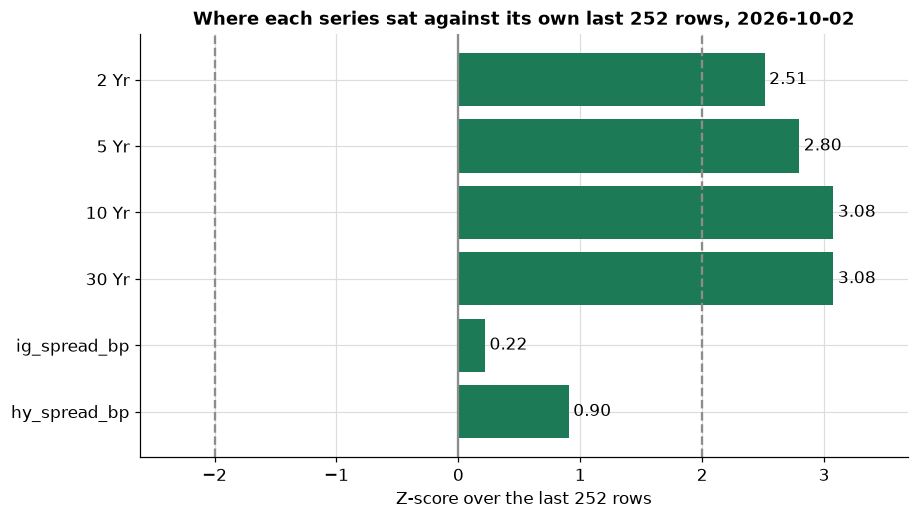

In [12]:
# z-score of each series over its last 252 rows; the dashed lines are 2 standard deviations either side of the average
lv = tables["levels"]
fig, ax = plt.subplots()
bars = ax.barh(lv.index, lv["zscore"], color="#1c7a57")
# the first series at the top, as in the table
ax.invert_yaxis()
ax.bar_label(bars, fmt="%.2f", padding=3)
ax.axvline(0, color="#8c8c8c")
for edge in (-2, 2):
    ax.axvline(edge, linestyle="--", color="#8c8c8c")
ax.set_axisbelow(True)
ax.margins(x=0.12)
ax.set_xlabel("Z-score over the last 252 rows")
ax.set_title(f"Where each series sat against its own last 252 rows, {AS_OF}")
plt.show()

* A bar is how many standard deviations the day's level sat from its 252-row average: zero is the average, and the dashed lines are two standard deviations either way. It describes where the level was in its own year, nothing more.

Q. The curve: every tenor on 2026-10-02 and on the previous market date.

In [13]:
# .bar draws a bar inside each cell of the change column, left of zero for a fall (Excel: Data Bars)
(tables["curve"].style
    .format({"years": "{:.3f}", "previous_pct": "{:.2f}", "as_of_pct": "{:.2f}", "chg_bp": "{:+.1f}"})
    .bar(subset=["chg_bp"], align="zero", color=["#f3d9b8", "#7fd1a8"])
    .set_caption("The curve on the as-of date and the previous market date: yields in percent, change in bp"))

,years,previous_pct,as_of_pct,chg_bp
tenor,,,,
1 Mo,0.083,4.06,4.04,-2.0
1.5 Month,0.125,4.10,4.09,-1.0
2 Mo,0.167,4.13,4.11,-2.0
3 Mo,0.250,4.17,4.19,+2.0
4 Mo,0.333,4.26,4.26,+0.0
6 Mo,0.500,4.27,4.27,+0.0
1 Yr,1.000,4.44,4.46,+2.0
2 Yr,2.000,4.78,4.83,+5.0
3 Yr,3.000,4.91,4.96,+5.0


* 14 tenors in order of years, with the previous market date, 2026-10-01, beside the as-of date and the change in bp. From the 1 Yr out, every tenor moved between +2 and +5 bp.
* The table shows the changes rounded to one decimal. The numbers underneath are not quite whole: the 5 Yr's is `4.999999999999982`, 5.06 less 5.01 in binary floating point, times 100. It is 5 bp to the precision the file holds, and Excel's own subtraction gives the same thing (Excel Side by Side).

Q. Draw the change at each tenor.

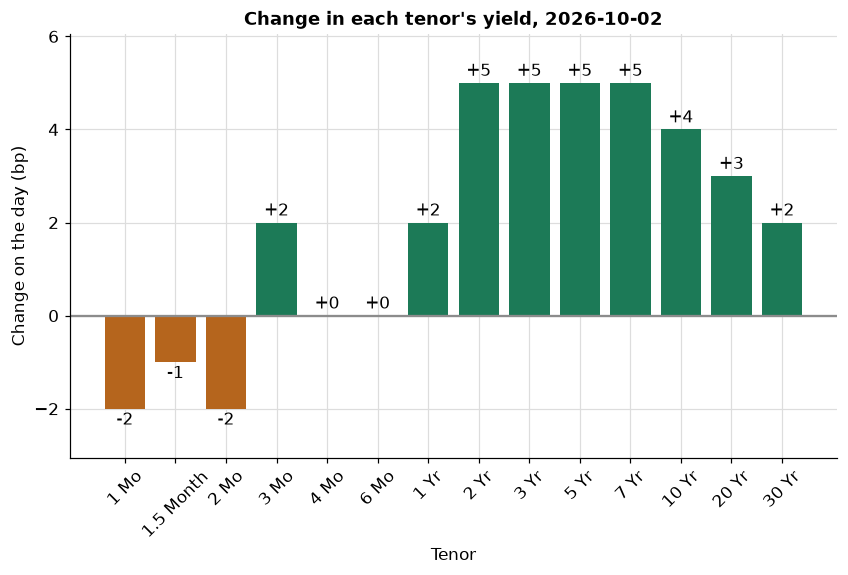

In [14]:
# one bar for each tenor: green for a rise, orange for a fall, in bp
curve_change = tables["curve"]
fig, ax = plt.subplots()
bars = ax.bar(curve_change.index, curve_change["chg_bp"], color=["#1c7a57" if v >= 0 else "#b5651d" for v in curve_change["chg_bp"]])
ax.bar_label(bars, fmt="%+.0f", padding=2)
ax.axhline(0, color="#8c8c8c")
ax.set_axisbelow(True)
ax.margins(y=0.15)
ax.tick_params(axis="x", rotation=45)
ax.set_xlabel("Tenor")
ax.set_ylabel("Change on the day (bp)")
ax.set_title(f"Change in each tenor's yield, {AS_OF}")
plt.show()

* The shape of the day in one picture: where yields fell, where they rose, and by how many bp. The previous chart and this one use the same two columns of the table.

Q. The slopes and the flies.

In [15]:
# a styled table again: the gradient shades the percentile rank (Excel: Conditional Formatting, Color Scales)
(tables["slopes_flies"].style
    .format({"level": "{:.1f}", "chg_1d_bp": "{:+.1f}", "chg_1w_bp": "{:+.1f}", "chg_1m_bp": "{:+.1f}",
             "zscore": "{:.2f}", "pct_rank": "{:.1f}"})
    .background_gradient(subset=["pct_rank"], cmap="Greens")
    .set_caption("Slopes and flies in bp: level, changes over 1 day, 1 week, 1 month, z-score and percentile rank"))

,unit,level,chg_1d_bp,chg_1w_bp,chg_1m_bp,zscore,pct_rank
series,,,,,,,
2s10s,bp,45.0,-1.0,+9.0,+5.0,-0.51,28.2
5s30s,bp,57.0,-3.0,+6.0,-16.0,-2.07,6.0
3m10y,bp,109.0,+2.0,+16.0,+22.0,2.07,100.0
2s5s10s,bp,1.0,+1.0,+3.0,+11.0,2.70,98.8
5s10s30s,bp,-13.0,+1.0,+0.0,+10.0,2.58,100.0


* 2s10s was 45 bp, down 1 bp on the day, with 28.2 percent of its last 252 values at or below it. 5s30s was 57 bp, with a percentile rank of 6.0.
* Day 9's signs: a slope is the long yield less the short one, and a fly is twice the belly less both wings.

Q. Draw how each shape changed over a day, a week, and a month.

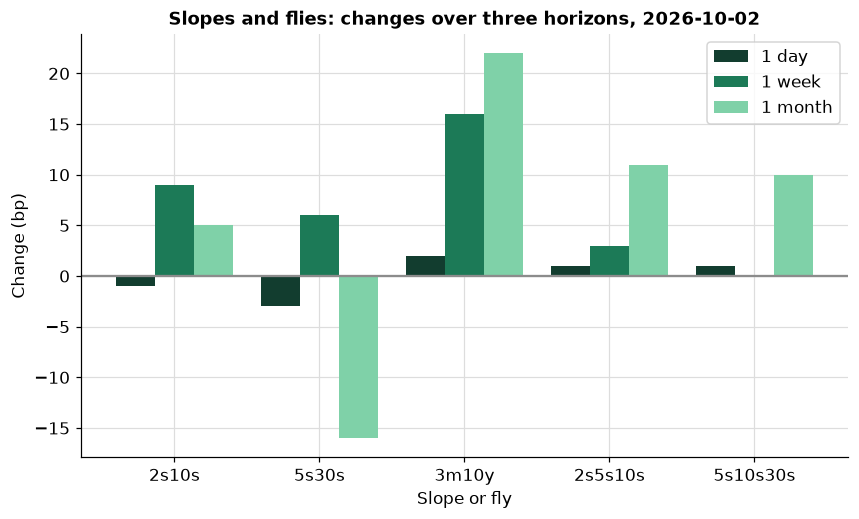

In [16]:
# three bars for each shape: its change over 1 day, 1 week, and 1 month, in bp
shapes = tables["slopes_flies"]
positions = list(range(len(shapes)))
fig, ax = plt.subplots()
ax.bar([p - 0.27 for p in positions], shapes["chg_1d_bp"], width=0.27, label="1 day")
ax.bar(positions, shapes["chg_1w_bp"], width=0.27, label="1 week")
ax.bar([p + 0.27 for p in positions], shapes["chg_1m_bp"], width=0.27, label="1 month")
ax.axhline(0, color="#8c8c8c")
ax.set_xticks(positions, shapes.index)
ax.set_axisbelow(True)
ax.set_xlabel("Slope or fly")
ax.set_ylabel("Change (bp)")
ax.set_title(f"Slopes and flies: changes over three horizons, {AS_OF}")
ax.legend()
plt.show()

* Each group of three bars is one shape: its change over a day, a week, and a month, in bp. A bar below zero is a shape that narrowed or fell over that horizon. This is description: it says what happened, not what it means.

Q. What does it do with a date that has no row, such as Labor Day, 2026-09-07?

In [17]:
try:
    md.snapshot_tables(market, book, "2026-09-07", SNAPSHOT_UNITS)
except ValueError as error:
    print(f"ValueError: {error}")

ValueError: 2026-09-07 is not a market date: market has no row for it


* It stops and says why. A snapshot for a day the market had no curve would have to borrow a day's numbers from somewhere, and borrowing is exactly what this course never does silently.

Q. Does the snapshot for 2026-09-30 use only rows on or before that date? Build it from the whole file and from the file cut at 2026-09-30, and compare every table.

In [18]:
full = md.snapshot_tables(market, book, "2026-09-30", SNAPSHOT_UNITS)
cut_at = md.snapshot_tables(market.loc[:"2026-09-30"], book, "2026-09-30", SNAPSHOT_UNITS)
# exact equality, table by table: the rows after 2026-09-30 change nothing
for name in full:
    pd.testing.assert_frame_equal(full[name], cut_at[name], check_exact=True)
print(f"all {len(full)} tables equal; the 10 Yr on 2026-09-30: {full['levels'].loc['10 Yr', 'level']} percent")

all 4 tables equal; the 10 Yr on 2026-09-30: 5.29 percent


* Every table is identical, to the last digit. The file runs two more market days past 2026-09-30, and the snapshot for 2026-09-30 never sees them: the 10 Yr is 5.29 percent, its value that day.

Q. Add the first two tests: the snapshot uses the as-of date and not the last row, and it refuses a date that is not a market date.

In [19]:
%%writefile -a test_marketdata.py


from matplotlib.figure import Figure  # a chart without a screen, from day 14

# the market columns on the snapshot and their units
SNAPSHOT_UNITS = {"2 Yr": "pct", "5 Yr": "pct", "10 Yr": "pct", "30 Yr": "pct", "ig_spread_bp": "bp", "hy_spread_bp": "bp"}


def snapshot_inputs() -> tuple[pd.DataFrame, pd.DataFrame]:
    """The market (the Treasury file joined to the synthetic spreads) and the September book."""
    spreads = pd.read_csv(HERE / "course3_synthetic_spreads.csv", parse_dates=["date"], index_col="date")
    market = read_treasury().join(spreads, validate="one_to_one")
    return market, pd.read_csv(HERE / "holdings.csv")


def test_snapshot_uses_as_of_not_last_row():
    market, book = snapshot_inputs()
    tables = md.snapshot_tables(market, book, "2026-09-30", SNAPSHOT_UNITS)
    # the file runs to 2026-10-02, but the snapshot for 2026-09-30 shows 2026-09-30
    assert tables["levels"].loc["10 Yr", "level"] == 5.29
    assert tables["curve"].loc["10 Yr", "as_of_pct"] == 5.29
    assert tables["curve"].loc["10 Yr", "previous_pct"] == market.loc["2026-09-29", "10 Yr"]
    assert tables["levels"].attrs["as_of"] == "2026-09-30"
    total = tables["book"].set_index("by").loc["total"]
    assert total["bonds"] == 200


def test_snapshot_rejects_non_market_date():
    market, book = snapshot_inputs()
    with pytest.raises(ValueError):
        md.snapshot_tables(market, book, "2026-09-07", SNAPSHOT_UNITS)

Appending to test_marketdata.py


* `snapshot_inputs` loads the market and the book the way the notebook did. Both tests use it.
* `test_snapshot_uses_as_of_not_last_row` builds the snapshot for 2026-09-30 from a file that runs to 2026-10-02 and checks the level, the curve, the previous date, the date the tables carry, and the book's bond count.

## 14.3 The Book Section: DV01 and a What-If

The book section joins the market to the synthetic September book. It answers two mechanical questions:

* **How much does the book's value change for 1 bp?** Each bond's DV01 from `bondmath.dv01`, in price points per 100 of face, times its face over 100, gives a position DV01 in dollars per bp. They are computed at the book's own date, 2026-09-30, the date its prices and yields are for.
* **What if each bond's yield had moved by the day's curve change at its maturity?** `_book_section` reads the curve table's `chg_bp` column, interpolates it at each bond's years to maturity with `bondmath.interpolate_yield` (flat beyond the 1 Mo and 30 Yr ends), reprices the bond at its yield plus that move with `bondmath.dirty_price`, and multiplies the change in price by its face over 100.

**This is a what-if, not a profit and loss.** It applies the day's real Treasury curve change, and nothing else, to a synthetic book: no spread change, no carry, no trading, and a book dated 2026-09-30. It shows the book's sensitivity to that one move, mechanically, and that is all it says.

Q. Show the book table.

In [20]:
# .bar draws a data bar in the DV01 column; .format gives money its commas and cents
(tables["book"].style
    .format({"bonds": "{:,}", "face_usd": "{:,.0f}", "market_value_usd": "{:,.2f}", "dv01_usd": "{:,.2f}", "mv_change_usd": "{:,.2f}"})
    .bar(subset=["dv01_usd"], color="#7fd1a8")
    .set_caption("The synthetic book by sector and rating bucket: face, market value, DV01 (dollars per bp), and the what-if change (dollars)"))

,by,group,bonds,face_usd,market_value_usd,dv01_usd,mv_change_usd
0,sector,Consumer,26,"56,250,000","56,629,597.50","39,489.93","-141,976.11"
1,sector,Energy,17,"39,250,000","38,830,005.00","23,542.53","-95,748.51"
2,sector,Financials,26,"69,250,000","68,219,672.50","42,434.63","-180,078.73"
3,sector,Health Care,20,"39,000,000","38,908,187.50","19,941.82","-79,436.23"
4,sector,Industrials,20,"50,750,000","52,540,745.00","35,177.59","-131,533.38"
5,sector,Materials,26,"70,500,000","71,701,617.50","37,739.11","-147,403.43"
6,sector,Technology,12,"30,000,000","30,311,760.00","16,572.55","-71,214.93"
7,sector,Telecom,21,"54,750,000","55,848,270.00","34,384.38","-137,426.20"
8,sector,Transportation,20,"50,000,000","48,822,897.50","39,971.07","-134,671.72"
9,sector,Utilities,12,"29,250,000","29,006,462.50","17,742.51","-73,808.67"


* 10 sectors, then 7 rating buckets (the rating with its `+` or `-` removed), then the whole book: 200 bonds, 489,000,000 dollars of face, 490,819,215.00 dollars of market value.
* The book's DV01 is 306,996.11 dollars per bp. Financials has the largest sector DV01, 42,434.63 dollars, and BBB the largest rating bucket DV01, 109,668.71 dollars.
* The mechanical change for the curve move of 2026-10-02 is -1,193,297.89 dollars: yields rose at every maturity the book holds, so every group's value falls in the what-if.
* DV01 is the change in a position's value for 1 bp, in dollars. A rating bucket is the rating with its `+` or `-` removed, so BBB+ and BBB- sit together.

Q. Draw the DV01 by sector and by rating bucket.

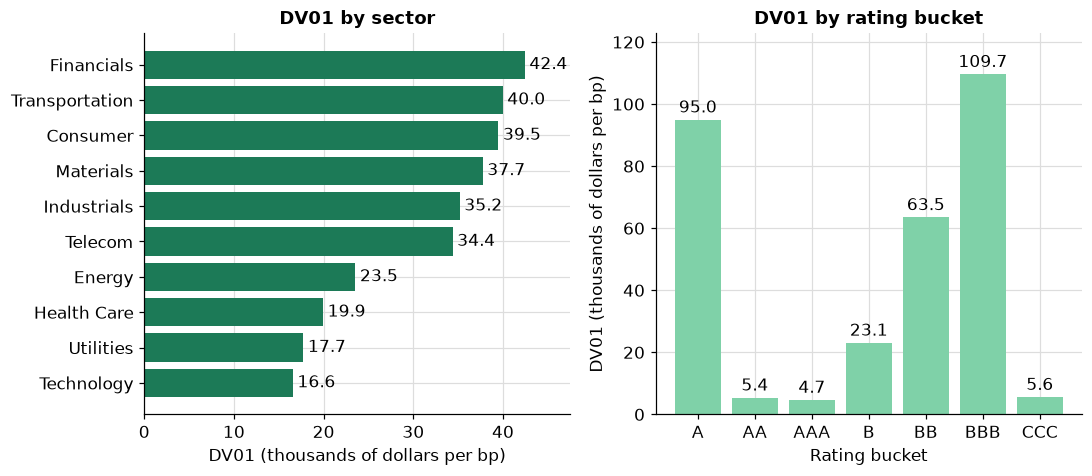

In [21]:
# left: the sectors, smallest at the bottom. right: the rating buckets in the order of the table
bt = tables["book"]
sectors = bt[bt["by"] == "sector"].sort_values("dv01_usd", ascending=False)
buckets = bt[bt["by"] == "rating bucket"]
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.5))
bars = left.barh(sectors["group"], sectors["dv01_usd"] / 1000, color="#1c7a57")
left.invert_yaxis()
left.bar_label(bars, fmt="%.1f", padding=3)
left.set_xlabel("DV01 (thousands of dollars per bp)")
left.set_title("DV01 by sector")
left.margins(x=0.12)
bars = right.bar(buckets["group"], buckets["dv01_usd"] / 1000, color="#7fd1a8")
right.bar_label(bars, fmt="%.1f", padding=2)
right.set_xlabel("Rating bucket")
right.set_ylabel("DV01 (thousands of dollars per bp)")
right.set_title("DV01 by rating bucket")
right.margins(y=0.12)
for ax in (left, right):
    ax.set_axisbelow(True)
plt.show()

* Each side splits the same total DV01 a different way: by sector on the left, by rating bucket on the right. The next cell proves both add back to the book.

Q. Draw the what-if: the change in market value from the day's curve move, by sector.

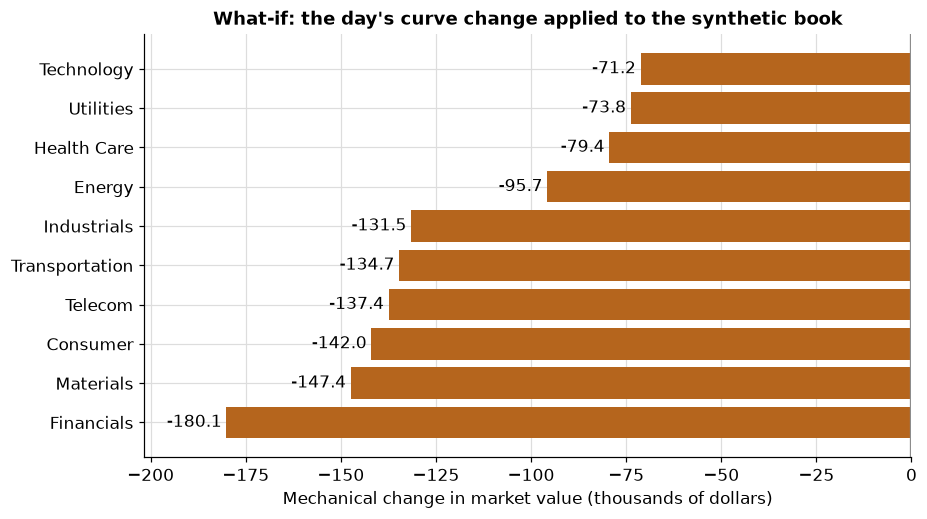

In [22]:
# the what-if applies the day's real curve change to the synthetic book; every sector falls because yields rose
by_move = bt[bt["by"] == "sector"].sort_values("mv_change_usd")
fig, ax = plt.subplots()
bars = ax.barh(by_move["group"], by_move["mv_change_usd"] / 1000, color="#b5651d")
ax.bar_label(bars, fmt="%.1f", padding=3)
ax.axvline(0, color="#8c8c8c")
ax.set_axisbelow(True)
ax.margins(x=0.12)
ax.set_xlabel("Mechanical change in market value (thousands of dollars)")
ax.set_title("What-if: the day's curve change applied to the synthetic book")
plt.show()

* A what-if, not a profit and loss: only the Treasury curve change moves, on a synthetic book. Compare with the DV01 chart: for the same move, a larger DV01 means a larger mechanical change.

Q. Do the sectors and the rating buckets each add back to the book?

In [23]:
book_table = tables["book"]
total = book_table[book_table["by"] == "total"].iloc[0]
for by in ["sector", "rating bucket"]:
    groups = book_table[book_table["by"] == by]
    # each way of splitting the book must add back to the whole book, to the cent
    for column in ["bonds", "face_usd", "market_value_usd", "dv01_usd", "mv_change_usd"]:
        assert abs(groups[column].sum() - total[column]) < 0.005, f"{by} {column} does not add up"
    print(f"{by}: {len(groups)} groups add up to {total['bonds']} bonds and {total['dv01_usd']:,.2f} dollars of DV01")

sector: 10 groups add up to 200 bonds and 306,996.11 dollars of DV01
rating bucket: 7 groups add up to 200 bonds and 306,996.11 dollars of DV01


* Both splits add back to the whole book on every column, to the cent. A control total like this is cheap to write and stops a report with a lost or doubled group.

Q. Put the what-if beside the DV01. How many bp of move does the change correspond to?

In [24]:
# the change divided by the DV01: the DV01-weighted average move, in bp, at the bonds' maturities
average_move_bp = -total["mv_change_usd"] / total["dv01_usd"]
print(f"change {total['mv_change_usd']:,.2f} dollars / DV01 {total['dv01_usd']:,.2f} dollars per bp = {average_move_bp:.2f} bp")

change -1,193,297.89 dollars / DV01 306,996.11 dollars per bp = 3.89 bp


* About 3.9 bp: inside the range of the curve's moves from the 1 Yr out, +2 to +5 bp, weighted toward the maturities where the book's DV01 sits. For 2026-09-30 the same division gives 3.2 bp. It is an approximate check: a full reprice also carries a little convexity, which the DV01 leaves out.

## 14.4 Charts

Two charts go on the page: the curve on both days, and the synthetic spreads over their last 252 market days, labelled synthetic in the title and the legend.

Q. Draw the curve on the as-of date and on the previous market date.

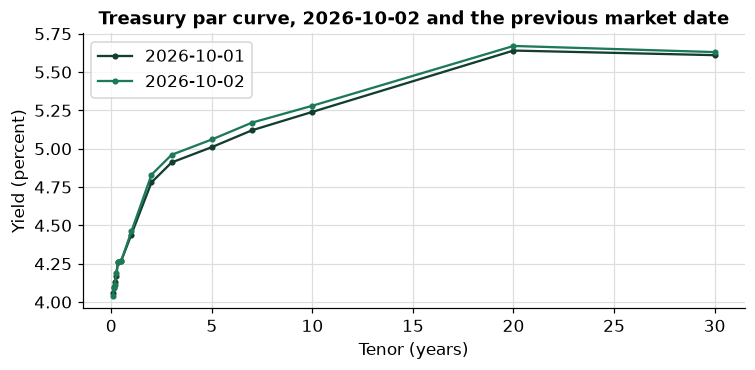

In [25]:
curve = tables["curve"]
# the previous market date: the row before AS_OF in the market's own calendar
previous_date = market.index[market.index.get_loc(pd.Timestamp(AS_OF)) - 1]

curve_figure, axes = plt.subplots(figsize=(7, 3.5))
axes.plot(curve["years"], curve["previous_pct"], marker="o", markersize=3, label=f"{previous_date:%Y-%m-%d}")
axes.plot(curve["years"], curve["as_of_pct"], marker="o", markersize=3, label=AS_OF)
axes.set_title(f"Treasury par curve, {AS_OF} and the previous market date")
axes.set_xlabel("Tenor (years)")
axes.set_ylabel("Yield (percent)")
axes.legend()
curve_figure.tight_layout()
plt.show()

* The two lines nearly overlap: a few bp is small against a curve that runs from 4.04 to 5.67 percent. The table carries the moves; the chart carries the shape.

Q. Draw the synthetic spreads over the last 252 market days.

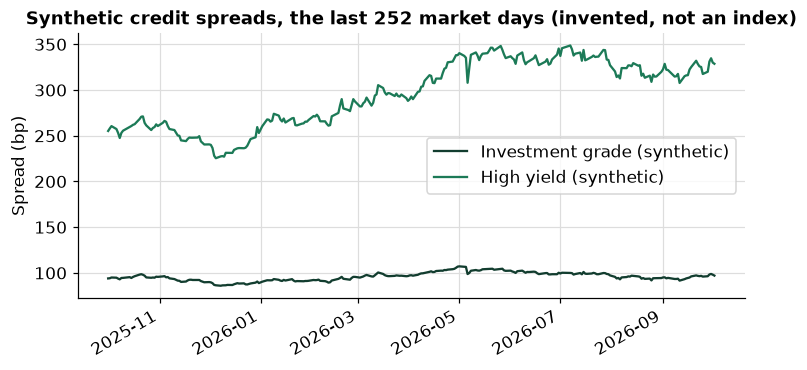

In [26]:
recent = market.loc[:AS_OF, ["ig_spread_bp", "hy_spread_bp"]].tail(252)

spread_figure, axes = plt.subplots(figsize=(7, 3.5))
axes.plot(recent.index, recent["ig_spread_bp"], label="Investment grade (synthetic)")
axes.plot(recent.index, recent["hy_spread_bp"], label="High yield (synthetic)")
axes.set_title("Synthetic credit spreads, the last 252 market days (invented, not an index)")
axes.set_ylabel("Spread (bp)")
axes.legend()
# slant the date labels so they do not overlap
spread_figure.autofmt_xdate()
spread_figure.tight_layout()
plt.show()

* The same 252 rows the z-score and the percentile rank of each spread are computed over, so the chart and the levels table describe the same window.
* `plt.show()` draws each chart in the notebook. The figure objects, `curve_figure` and `spread_figure`, are still there afterwards, so the next section can save them into the page.

## 14.5 `write_snapshot_html` and `write_snapshot_excel`

The same tables go out two ways: an HTML page anyone can open in a browser, and a workbook for anyone who wants the numbers in Excel.

The HTML page is built as text. `DataFrame.to_html` turns each table into an HTML table, and each chart is saved as a PNG into memory and written into the page as base64 text, so the page is **one self-contained file**: nothing to lose when it is emailed or moved. No template library is needed.

Q. Add the two writers to `marketdata.py`, then reload it.

In [27]:
%%writefile -a marketdata.py


def write_snapshot_html(tables: dict[str, pd.DataFrame], figures: dict[str, Figure], path: Path, title: str) -> Path:
    """Write the snapshot as one self-contained HTML file and return its path.

    Units: as in the tables (numbers shown to 2 decimals). Convention: the title, the as-of date (from the
    tables' attrs, set by snapshot_tables), the disclaimer, each table as DataFrame.to_html, each chart as a
    PNG embedded in base64 (no separate image files), the data sources, and the synthetic label. Describes the
    data; it contains no forecast and no recommendation. Uses no template library.
    Raises ValueError if the tables carry no as-of date.
    """
    as_of = tables["levels"].attrs.get("as_of")
    if as_of is None:
        raise ValueError("the tables carry no as-of date; build them with snapshot_tables")
    parts = [f"<h1>{html.escape(title)}</h1>", f"<p>As of {as_of}.</p>",
             f"<p><em>{html.escape(DISCLAIMER)}</em></p>"]
    # each table, numbers to 2 decimals with thousands separators
    for name, table in tables.items():
        parts.append(f"<h2>{html.escape(name)}</h2>")
        parts.append(table.to_html(float_format="{:,.2f}".format))
    # each chart as a PNG held inside the file
    for name, figure in figures.items():
        buffer = io.BytesIO()
        figure.savefig(buffer, format="png", dpi=100)
        encoded = base64.b64encode(buffer.getvalue()).decode("ascii")
        parts.append(f"<h2>{html.escape(name)}</h2>")
        parts.append(f'<img alt="{html.escape(name)}" src="data:image/png;base64,{encoded}">')
    parts.append(f"<p>{html.escape(SOURCES)}</p>")
    parts.append("<p>The credit spreads and the book are synthetic.</p>")
    page = ("<!DOCTYPE html>\n<html lang=\"en\">\n<head>\n<meta charset=\"utf-8\">\n"
            f"<title>{html.escape(title)}</title>\n</head>\n<body>\n" + "\n".join(parts) + "\n</body>\n</html>\n")
    path = Path(path)
    path.write_text(page, encoding="utf-8", newline="\n")
    return path


def write_snapshot_excel(tables: dict[str, pd.DataFrame], path: Path) -> Path:
    """Write the snapshot tables to one Excel workbook and return its path.

    Units: as in the tables. Convention: pd.ExcelWriter with openpyxl. The first sheet, about, holds the as-of
    date (from the tables' attrs, set by snapshot_tables), the data sources, the synthetic label, and the
    disclaimer, so the workbook describes itself as the HTML page does. Then one sheet per table, named by its
    key, holding the table with its index.
    Raises ValueError if the tables carry no as-of date.
    """
    as_of = tables["levels"].attrs.get("as_of")
    if as_of is None:
        raise ValueError("the tables carry no as-of date; build them with snapshot_tables")
    # what the workbook is, on its first sheet
    about = pd.DataFrame({"value": [as_of, SOURCES, "The credit spreads and the book are synthetic.", DISCLAIMER]},
                         index=pd.Index(["as_of", "sources", "synthetic", "disclaimer"], name="item"))
    path = Path(path)
    with pd.ExcelWriter(path, engine="openpyxl") as writer:
        about.to_excel(writer, sheet_name="about")
        for name, table in tables.items():
            table.to_excel(writer, sheet_name=name)
    return path

Appending to marketdata.py


In [28]:
importlib.reload(md)
print(f"the writers are in marketdata: {all(name in own_functions(md) for name in ['write_snapshot_html', 'write_snapshot_excel'])}")

the writers are in marketdata: True


* `html.escape` makes text safe to put inside HTML: a `<`, `>`, `&`, or quote in a title or a source line becomes a code the browser shows as the character.
* The date on the page comes from `tables["levels"].attrs["as_of"]`, and the function stops if it is missing.
* `write_snapshot_excel` is `pd.ExcelWriter` with openpyxl. Its first sheet, `about`, holds the as-of date (from the same `attrs`), the sources, the synthetic label, and the disclaimer; then comes one sheet per table, named by its key: the Course 2 day 14 pattern.

Q. Write the page into a `snapshots` folder inside the work folder.

In [29]:
snapshots = work / "snapshots"
snapshots.mkdir(exist_ok=True)

figures = {"Treasury curve": curve_figure, "Synthetic credit spreads": spread_figure}
html_path = md.write_snapshot_html(tables, figures, snapshots / f"snapshot_{AS_OF}.html", f"Daily market snapshot, {AS_OF}")
# the path inside the work folder only: the full path would show your user name
print(f"wrote {html_path.relative_to(work).as_posix()}")

wrote snapshots/snapshot_2026-10-02.html


Q. Read the page back as text. Which headings does it have, in order? The standard library's `html.parser` reads HTML; a small class collects the text of every `h1` and `h2`.

In [30]:
from html.parser import HTMLParser


class Headings(HTMLParser):
    """Collect the text of every h1 and h2 element of a page, in order."""

    def __init__(self):
        super().__init__()
        self.found = []
        self.inside = False

    def handle_starttag(self, tag, attrs):
        self.inside = tag in ("h1", "h2")

    def handle_endtag(self, tag):
        self.inside = False

    def handle_data(self, data):
        if self.inside:
            self.found.append(data)


page = html_path.read_text(encoding="utf-8")
headings = Headings()
headings.feed(page)
print(headings.found)

['Daily market snapshot, 2026-10-02', 'levels', 'curve', 'slopes_flies', 'book', 'Treasury curve', 'Synthetic credit spreads']


* The title, the four tables, and the two charts, in the order the function wrote them.

Q. Check the rest of the page with plain string tests: the date, the disclaimer, the sources, the synthetic label, four tables, two charts, and no path or user name from this machine.

In [31]:
import getpass
import html
import re

# the page without its embedded images: base64 text is random letters and could spell anything
words = re.sub(r"data:image/png;base64,[A-Za-z0-9+/=]+", "", page)
page_checks = {
    "the as-of date": f"As of {AS_OF}." in words,
    "the disclaimer": md.DISCLAIMER in words,
    # html.escape turned the apostrophe in Moody's into a code, so look for the escaped text
    "the data sources": html.escape(md.SOURCES) in words,
    "the synthetic label": "The credit spreads and the book are synthetic." in words,
    "four tables": words.count("<table") == 4,
    "two embedded charts": page.count("data:image/png;base64,") == 2,
    "no work folder path": str(work) not in words and work.name not in words,
    "no user name": getpass.getuser() not in words,
}
for check_name, passed in page_checks.items():
    print(f"{check_name}: {passed}")
assert all(page_checks.values()), "the page is missing something"

the as-of date: True
the disclaimer: True
the data sources: True
the synthetic label: True
four tables: True
two embedded charts: True
no work folder path: True
no user name: True


* Every check passes. `getpass.getuser()` is your Windows user name: the check compares it with the page and never prints it.
* To look at the page, open it in your browser from the `snapshots` folder of the work folder. In PowerShell: `Invoke-Item "$env:TEMP\<work folder>\snapshots\snapshot_2026-10-02.html"`, with the work folder's name from the setup cell.

Q. Write the workbook, then read it back with `pd.read_excel` and compare.

In [32]:
xlsx_path = md.write_snapshot_excel(tables, snapshots / f"snapshot_{AS_OF}.xlsx")
print(f"wrote {xlsx_path.relative_to(work).as_posix()}")

# sheet_name=None reads every sheet into a dictionary, in the workbook's order
back = pd.read_excel(xlsx_path, sheet_name=None, index_col=0)
print(f"sheets: {list(back)}")
print(f"about: as of {back['about'].loc['as_of', 'value']}")
for name, table in tables.items():
    print(f"{name}: {len(back[name])} rows read back, {len(table)} written")

# the numbers survive the trip through the file
pd.testing.assert_frame_equal(back["levels"], tables["levels"], check_exact=False, rtol=1e-12, check_dtype=False)
print("levels: equal after the round trip")

wrote snapshots/snapshot_2026-10-02.xlsx
sheets: ['about', 'levels', 'curve', 'slopes_flies', 'book']
about: as of 2026-10-02
levels: 6 rows read back, 6 written
curve: 14 rows read back, 14 written
slopes_flies: 5 rows read back, 5 written
book: 18 rows read back, 18 written
levels: equal after the round trip


* Five sheets: `about` first, with the as-of date, then the four tables in the order of the dictionary, every row back, and the levels table equal to twelve significant digits.

**What Excel shows.** Tested in Excel: the workbook this notebook writes was opened in desktop Excel with `Workbooks.Open`. It has five sheets, `about`, `levels`, `curve`, `slopes_flies`, and `book`, in that order. On `about`, column A names each item and column B holds it: `as_of` 2026-10-02, then the sources, the synthetic label, and the disclaimer. On the table sheets, row 1 holds the column names and column A the table's index: the series names, the tenors, and, on `book`, the row numbers 0 to 17. No format was set, so Excel shows each number in its General format, as many digits as fit a column of the standard width (8.09 characters, every column): the `10 Yr` row of `levels` shows `10 Yr | pct | 5.28 | 4 | 11 | 49 | 3.075234 | 99.60317`, and the total row of `book` shows `17 | total | book | 200 | 4.89E+08 | 4.91E+08 | 306996.1 | -1193298`. A cell holds every digit even where it shows fewer: Consumer's market value shows `56629598` and holds 56629597.5, which the formula bar shows when you click the cell. No cell showed `####`.

* The `about` sheet carries the as-of date, as the HTML page does, so a workbook forwarded on its own still says which day it describes and that its spreads and book are synthetic. Exercise 3 puts the date in the file name as well.

Q. Add the last two tests: the page holds the date, the disclaimer, the synthetic label, a chart, and four tables; the workbook round-trips.

In [33]:
%%writefile -a test_marketdata.py


def test_html_contains_as_of_and_disclaimer(tmp_path):
    market, book = snapshot_inputs()
    tables = md.snapshot_tables(market, book, "2026-10-02", SNAPSHOT_UNITS)
    # one small chart of the curve, drawn without a screen
    figure = Figure(figsize=(4, 3))
    axes = figure.subplots()
    axes.plot(tables["curve"]["years"], tables["curve"]["as_of_pct"])
    path = md.write_snapshot_html(tables, {"curve": figure}, tmp_path / "snapshot.html", "Daily market snapshot")
    text = path.read_text(encoding="utf-8")
    assert "As of 2026-10-02." in text
    assert md.DISCLAIMER in text
    assert "synthetic" in text and "data:image/png;base64," in text
    assert text.count("<table") == 4


def test_excel_round_trip(tmp_path):
    market, book = snapshot_inputs()
    tables = md.snapshot_tables(market, book, "2026-10-02", SNAPSHOT_UNITS)
    path = md.write_snapshot_excel(tables, tmp_path / "snapshot.xlsx")
    back = pd.read_excel(path, sheet_name=None, index_col=0)
    # the about sheet first, with the as-of date and the disclaimer, then one sheet per table
    assert list(back) == ["about", *tables]
    assert back["about"].loc["as_of", "value"] == "2026-10-02"
    assert back["about"].loc["disclaimer", "value"] == md.DISCLAIMER
    for name, table in tables.items():
        assert len(back[name]) == len(table)
    levels = back["levels"]
    levels.index.name = tables["levels"].index.name
    pd.testing.assert_frame_equal(levels, tables["levels"], check_exact=False, rtol=1e-12, check_dtype=False)

Appending to test_marketdata.py


* Both use pytest's `tmp_path`, so a test never writes into your folder.
* The page test draws its chart with `Figure` from `matplotlib.figure`, not with `plt`: a test, like a script, has no screen.

Q. Run the tests.

In [34]:
# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_marketdata.py"],
                        cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.......................................................                  [100%]
55 passed in 2.74s



* `55 passed`: the 51 from days 1 to 13 and today's 4.

## 14.6 Automation: `snapshot.py`

Everything above ran in a notebook, one cell at a time. A snapshot that goes out every morning should run with **one command** and no notebook: a script. `snapshot.py` does the whole job: it loads the data, builds the tables, draws the charts, and writes both files, for whatever date it is given on the command line.

* **`argparse`**, from the standard library, reads `--as-of 2026-09-30` from the command line and writes the `--help` text. With no `--as-of`, the script uses the last date in the market data.
* **`HERE`** is the folder the script is in. The script reads its data and writes its output there, whichever folder it is started from.
* **`Figure`** draws a chart with no screen, as the test does.
* **A bad date** gives a one-line message and exit code 2 through `parser.error`, not a traceback: a traceback prints the script's full path, and with it your user name.

Q. Write `snapshot.py` into the work folder.

In [35]:
%%writefile snapshot.py
"""snapshot.py: write the daily market snapshot for one market date, as HTML and as Excel.

Usage, from any folder:
    python snapshot.py --as-of 2026-10-02
    python snapshot.py                      (the last date in the market data)

It reads the Treasury file, the synthetic spreads, and the synthetic book from the folder this file is in, and
writes snapshots/snapshot_YYYY-MM-DD.html and .xlsx there. It describes the data and forecasts nothing.
"""
import argparse
from pathlib import Path

import pandas as pd
from matplotlib.figure import Figure

import marketdata as md

# the folder this file is in, whichever folder the script is started from
HERE = Path(__file__).resolve().parent
# the market columns on the levels table, and their units
UNITS = {"2 Yr": "pct", "5 Yr": "pct", "10 Yr": "pct", "30 Yr": "pct", "ig_spread_bp": "bp", "hy_spread_bp": "bp"}


def load_market() -> pd.DataFrame:
    """The Treasury file (percent) joined to the synthetic spreads (bp), one row per market date."""
    options = {"parse_dates": ["date"], "index_col": "date", "float_precision": "round_trip"}
    treasury = pd.read_csv(HERE / "treasury_par_yields.csv", **options)
    spreads = pd.read_csv(HERE / "course3_synthetic_spreads.csv", **options)
    return treasury.join(spreads, validate="one_to_one")


def charts(tables: dict[str, pd.DataFrame], market: pd.DataFrame) -> dict[str, Figure]:
    """The two charts, drawn without a screen: the curve on both days, and the synthetic spreads."""
    as_of = pd.Timestamp(tables["levels"].attrs["as_of"])
    previous = market.index[market.index.get_loc(as_of) - 1]
    curve = tables["curve"]
    curve_figure = Figure(figsize=(7, 3.5))
    axes = curve_figure.subplots()
    axes.plot(curve["years"], curve["previous_pct"], marker="o", markersize=3, label=f"{previous:%Y-%m-%d}")
    axes.plot(curve["years"], curve["as_of_pct"], marker="o", markersize=3, label=f"{as_of:%Y-%m-%d}")
    axes.set_title(f"Treasury par curve, {as_of:%Y-%m-%d} and the previous market date")
    axes.set_xlabel("Tenor (years)")
    axes.set_ylabel("Yield (percent)")
    axes.legend()
    curve_figure.tight_layout()

    recent = market.loc[:as_of, ["ig_spread_bp", "hy_spread_bp"]].tail(252)
    spread_figure = Figure(figsize=(7, 3.5))
    axes = spread_figure.subplots()
    axes.plot(recent.index, recent["ig_spread_bp"], label="Investment grade (synthetic)")
    axes.plot(recent.index, recent["hy_spread_bp"], label="High yield (synthetic)")
    axes.set_title("Synthetic credit spreads, the last 252 market days (invented, not an index)")
    axes.set_ylabel("Spread (bp)")
    axes.legend()
    spread_figure.autofmt_xdate()
    spread_figure.tight_layout()
    return {"Treasury curve": curve_figure, "Synthetic credit spreads": spread_figure}


def main() -> None:
    parser = argparse.ArgumentParser(description="Write the daily market snapshot as HTML and Excel.")
    parser.add_argument("--as-of", help="the market date, YYYY-MM-DD (default: the last date in the market data)")
    args = parser.parse_args()

    market = load_market()
    book = pd.read_csv(HERE / "holdings.csv")
    as_of = args.as_of or f"{market.index[-1]:%Y-%m-%d}"
    try:
        tables = md.snapshot_tables(market, book, as_of, UNITS)
    except ValueError as error:
        # a one-line message and exit code 2, with no traceback: a traceback would print this file's full path
        parser.error(str(error))

    # the date as the tables carry it, YYYY-MM-DD, names both files
    as_of = tables["levels"].attrs["as_of"]
    out = HERE / "snapshots"
    out.mkdir(exist_ok=True)
    md.write_snapshot_html(tables, charts(tables, market), out / f"snapshot_{as_of}.html", f"Daily market snapshot, {as_of}")
    md.write_snapshot_excel(tables, out / f"snapshot_{as_of}.xlsx")
    print(f"snapshot for {as_of}: wrote snapshots/snapshot_{as_of}.html and snapshots/snapshot_{as_of}.xlsx")


if __name__ == "__main__":
    main()

Writing snapshot.py


Q. What does its help say? Run it with `--help`, through `subprocess`, the way pytest has run all course.

In [36]:
# sys.executable is the kernel's own Python; cwd=work runs it in the work folder
run = subprocess.run([sys.executable, "snapshot.py", "--help"], cwd=work, capture_output=True, text=True)
print(run.stdout)

usage: snapshot.py [-h] [--as-of AS_OF]

Write the daily market snapshot as HTML and Excel.

options:
  -h, --help     show this help message and exit
  --as-of AS_OF  the market date, YYYY-MM-DD (default: the last date in the
                 market data)



* `argparse` wrote this from the two lines that set up the parser. `--as-of` is optional.

Q. Run it for 2026-10-02 and for 2026-09-30.

In [37]:
for as_of in ["2026-10-02", "2026-09-30"]:
    run = subprocess.run([sys.executable, "snapshot.py", "--as-of", as_of], cwd=work, capture_output=True, text=True)
    print(run.stdout + run.stderr, end="")
    assert run.returncode == 0, f"snapshot.py stopped with exit code {run.returncode}"

print(sorted(path.name for path in snapshots.iterdir()))

snapshot for 2026-10-02: wrote snapshots/snapshot_2026-10-02.html and snapshots/snapshot_2026-10-02.xlsx


snapshot for 2026-09-30: wrote snapshots/snapshot_2026-09-30.html and snapshots/snapshot_2026-09-30.xlsx
['snapshot_2026-09-30.html', 'snapshot_2026-09-30.xlsx', 'snapshot_2026-10-02.html', 'snapshot_2026-10-02.xlsx']


* Two runs, four files. The run for 2026-10-02 wrote over the two files of section 14.5 with the same tables, from the same function.

Q. And for 2026-09-07, a day with no row?

In [38]:
run = subprocess.run([sys.executable, "snapshot.py", "--as-of", "2026-09-07"], cwd=work, capture_output=True, text=True)
print(f"exit code {run.returncode}")
print(run.stderr)

exit code 2
usage: snapshot.py [-h] [--as-of AS_OF]
snapshot.py: error: 2026-09-07 is not a market date: market has no row for it



* Exit code 2, the usage line, and the reason, from `snapshot_tables` itself. A scheduler or a colleague's script reads the exit code: 0 is success, anything else is not.

Q. **Rerun, do not redo.** Read the two `levels` sheets back and put them side by side.

In [39]:
columns = ["level", "chg_1d_bp", "chg_1m_bp", "zscore", "pct_rank"]
two_days = {as_of: pd.read_excel(snapshots / f"snapshot_{as_of}.xlsx", sheet_name="levels", index_col=0)[columns]
            for as_of in ["2026-09-30", "2026-10-02"]}
side_by_side = pd.concat(two_days, axis=1)
# a styled table: two decimals everywhere (Excel: Format Cells)
(side_by_side.style
    .format("{:.2f}")
    .set_caption("The levels sheet of each snapshot, side by side"))

* One function, two dates, two reports, and not one line of code changed between them. On 2026-09-30 the 10 Yr was 5.29 percent; on 2026-10-02, 5.28 percent.
* On 2026-09-30 the synthetic investment grade spread was 98.8 bp and the high yield spread 334.7 bp: the market-value weighted spreads of the September book's two grades, the date the synthetic file was pinned to.

Q. Draw the two reports' z-scores side by side.

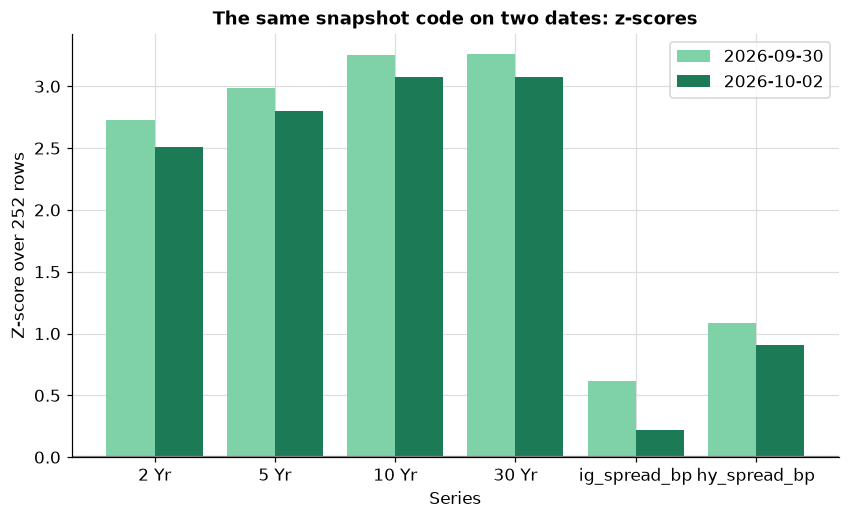

In [40]:
# the z-score column of each date's levels sheet, as two bars for each series
dates = list(two_days)
positions = list(range(len(two_days[dates[0]])))
fig, ax = plt.subplots()
ax.bar([p - 0.2 for p in positions], two_days[dates[0]]["zscore"], width=0.4, color="#7fd1a8", label=dates[0])
ax.bar([p + 0.2 for p in positions], two_days[dates[1]]["zscore"], width=0.4, color="#1c7a57", label=dates[1])
ax.axhline(0, color="#8c8c8c")
ax.set_xticks(positions, two_days[dates[0]].index)
ax.set_axisbelow(True)
ax.set_xlabel("Series")
ax.set_ylabel("Z-score over 252 rows")
ax.set_title("The same snapshot code on two dates: z-scores")
ax.legend()
plt.show()

* Same series, two dates, one function. The bars show how each series' position in its own year differed between the two days.

## 14.7 Running It Every Day: Windows Task Scheduler

Windows can run a command on a schedule with **Task Scheduler**, and `schtasks` is its command-line tool. These steps are for your own machine, shown as text; the notebook never runs them. The options used are the ones `schtasks /Create /?` lists (checked on Windows 11 for this course). **At work, your firm's policy decides whether scheduled tasks may run on your machine; follow it.**

Open a PowerShell terminal in VS Code with the course's `.venv` active, after Bring It Home has put `snapshot.py` in your `my_bondmath` folder.

**Step 1.** Find the full path of the Python that runs your code. With the `.venv` active, it is the venv's Python.

```powershell
$python = (Get-Command python).Source
```

**Step 2.** Create a daily task. `/TN` names it, `/SC DAILY` runs it every day, `/ST` sets the time (24-hour `HH:mm`), and `/TR` is the command. The help says a path with spaces needs a second set of quotes inside the outer ones, and that the inner ones can be single quotes, so both paths are wrapped in single quotes.

```powershell
schtasks /Create /TN "pfi_daily_snapshot" /SC DAILY /ST 18:30 /TR "'$python' '$HOME\projects\my_bondmath\snapshot.py'"
```

**Step 3.** Look at it, run it once now to test it, and delete it when you no longer want it.

```powershell
schtasks /Query /TN "pfi_daily_snapshot"
schtasks /Run /TN "pfi_daily_snapshot"
schtasks /Delete /TN "pfi_daily_snapshot" /F
```

With no `--as-of`, each run writes the snapshot for the last date in the data files. The course's files are frozen at 2026-10-02, so every run writes that same snapshot until the data is refreshed. A desk's version refreshes the data first; that is the job of a data feed, and of the capstone's extract tomorrow.

## Excel Side by Side

The snapshot workbook is ordinary Excel, so every number on it can be checked in Excel itself. Each line below was tested on exactly the workbook this notebook writes, opened in Excel 16.0 build 20430 on 2026-10-04 with `Workbooks.Open` and closed without saving.

| Job | Python | Excel (tested) | Excel returns |
| --- | --- | --- | --- |
| Open the snapshot | `md.write_snapshot_excel(tables, path)` | File, Open, `snapshot_2026-10-02.xlsx` | five sheets, `about`, `levels`, `curve`, `slopes_flies`, `book`; General format; no `####` |
| The curve's change in bp | `(curve["as_of_pct"] - curve["previous_pct"]) * 100` | `=(D2-C2)*100` on the `curve` sheet, filled down | matches `chg_bp` on every tenor, largest gap 8.9e-16 bp |
| The sectors add to the book's DV01 | `groups["dv01_usd"].sum()` | `=SUMIFS(G2:G19,B2:B19,"sector")` on the `book` sheet | 306,996.110402, the total row's 306,996.110402 |
| The buckets add to it too | the same, `by == "rating bucket"` | `=SUMIFS(G2:G19,B2:B19,"rating bucket")` | 306,996.110402 |
| The 10 Yr z-score on the levels sheet | `rolling_zscore`, 252 rows | `=STANDARDIZE(A252,AVERAGE(A1:A252),STDEV.S(A1:A252))` over the 252 10 Yr values to 2026-10-02 in A1:A252 | 3.075234405274332 |
| Its percentile rank | `rolling_percentile_rank`, 252 rows | `=COUNTIF(A1:A252,"<="&A252)/COUNT(A1:A252)*100` | 99.60317460317461 |

**Open it.** File, Open, and pick the workbook from the `snapshots` folder, or run the `Invoke-Item` line of section 14.5 with `.xlsx` at the end. The `about` sheet says what the workbook is and for which date; each sheet after it is one table: the names across row 1, the index down column A, as `to_excel` wrote them.

**The curve's change.** On the `curve` sheet the previous day's yields are in column C and the as-of day's in D. Type `=(D2-C2)*100` in F2 and fill it down to the last tenor: each cell is the change in bp, the same subtraction the Python line does on whole columns, and it matches column E, `chg_bp`, within 8.9e-16 bp: the same binary arithmetic, to the last bit.

**The control total.** On the `book` sheet column B says which split a row belongs to and column G holds the DV01. `SUMIFS(G2:G19,B2:B19,"sector")` adds the DV01 of the rows whose B is `sector`: the same total as the book row, and the same check the Python loop in 14.3 makes. Change `"sector"` to `"rating bucket"` for the other split.

**Check a number from its history.** Put the 252 10 Yr yields up to 2026-10-02 in A1:A252 of a new sheet, today last. `STANDARDIZE` of A252 with the window's `AVERAGE` and `STDEV.S` is day 8's z-score, and `COUNTIF` of the values at or below A252 over `COUNT` is the percentile rank. Both match the `levels` sheet's numbers for the 10 Yr: the percentile rank exactly (0.0e+00), the z-score within 4.6e-13, a difference in the last digits of two ways of summing the same 252 numbers.

Q. Do Excel's numbers match the snapshot's?

In [41]:
# what Excel returned in the test, typed from the test's record
excel_sector_dv01 = 306996.11040153407
excel_zscore = 3.075234405274332
excel_pct_rank = 99.60317460317461

ten = tables["levels"].loc["10 Yr"]
print(f"DV01 by sector, summed: gap {abs(excel_sector_dv01 - total['dv01_usd']):.1e} dollars")
print(f"z-score: gap {abs(excel_zscore - ten['zscore']):.1e}")
print(f"percentile rank: gap {abs(excel_pct_rank - ten['pct_rank']):.1e} percent")

DV01 by sector, summed: gap 5.8e-11 dollars
z-score: gap 4.6e-13
percentile rank: gap 0.0e+00 percent


* The same numbers, to the last digits a floating point sum can differ in.

## Save the Day with Git

Today's Git step: **commit the script, never its outputs.** The snapshots are rebuilt from the data by one command, so they do not belong in the record; `snapshot.py` does.

Q. Make the work folder a repository.

In [42]:
# stop here, with the steps to install it, if Git is not on this machine
if shutil.which("git") is None:
    raise RuntimeError("Git is not installed. Install Git for Windows from https://git-scm.com/downloads "
                       "(or run  winget install --id Git.Git  where your firm allows it), restart VS Code, "
                       "and run this cell again. Colab has Git already.")

# -C "{work}" points every Git command at the work folder, whatever folder the notebook is in
!git -C "{work}" --version
# make the work folder a repository
!git -C "{work}" init -q -b main
# settings for this repository only: a course name, a reserved example email, line endings left as they are,
# and no commit signing, so a signing setup on your machine does not ask for a key here
!git -C "{work}" config user.name "Course Student"
!git -C "{work}" config user.email "student@example.com"
!git -C "{work}" config core.autocrlf false
!git -C "{work}" config commit.gpgsign false

git version 2.50.1.windows.1


Q. Is Git working in the work folder, and only there?

In [43]:
# the guard: Git must report the work folder as the top of this repository, or the notebook stops
top = subprocess.run(["git", "-C", str(work), "rev-parse", "--show-toplevel"],
                     capture_output=True, text=True, check=True).stdout.strip()
assert os.path.samefile(top, work), "Git is not working in the work folder. Stop, and run the setup cell again."
print(f"Git is working in {work.name} and nowhere else")

Git is working in pfi_course3_14_t8dfjvks and nowhere else


Q. Write the `.gitignore` first, as on day 1.

In [44]:
%%writefile .gitignore
# secrets, downloads, databases, and the folders Python and pytest make
.env
cache/
*.db
__pycache__/
.pytest_cache/

Writing .gitignore


Q. Commit the module, the tests, and the `.gitignore`.

In [45]:
# the day's two files and the .gitignore, then the history so far
!git -C "{work}" add .gitignore marketdata.py test_marketdata.py
!git -C "{work}" commit -q -m "Add snapshot_tables, write_snapshot_html, write_snapshot_excel, and their tests"
!git -C "{work}" log --oneline

a0525e1 Add snapshot_tables, write_snapshot_html, write_snapshot_excel, and their tests


Q. What does Git see now?

In [46]:
# ?? marks a file Git sees but does not track
!git -C "{work}" status --short

?? bondmath.py
?? course3_excel_reference.csv
?? course3_fred_format_dgs10.json
?? course3_fred_format_dgs2.json
?? course3_synthetic_spreads.csv
?? holdings.csv
?? ratings.csv
?? snapshot.py
?? snapshots/
?? trade_blotter.csv
?? treasury_par_yields.csv


* `snapshot.py` is new, and so is the `snapshots/` folder. The data files and `bondmath.py` are copies the setup cell made, not today's work.

Q. Keep `snapshots/` out: add it to `.gitignore`, then look again, ignored files included.

In [47]:
%%writefile -a .gitignore
# the snapshot outputs: rebuilt by python snapshot.py, never committed
snapshots/

Appending to .gitignore


In [48]:
# --ignored lists the ignored files too, marked !!
!git -C "{work}" status --short --ignored

 M .gitignore
?? bondmath.py
?? course3_excel_reference.csv
?? course3_fred_format_dgs10.json
?? course3_fred_format_dgs2.json
?? course3_synthetic_spreads.csv
?? holdings.csv
?? ratings.csv
?? snapshot.py
?? trade_blotter.csv
?? treasury_par_yields.csv
!! __pycache__/
!! snapshots/


* `!! snapshots/`: ignored. `.gitignore` shows as modified and `snapshot.py` as new, the two files to commit.

Q. Commit them, then show the commit with the files it changed.

In [49]:
# --stat lists each file the commit changed; -1 shows only the last commit
!git -C "{work}" add .gitignore snapshot.py
!git -C "{work}" commit -q -m "Add snapshot.py, which writes the snapshot for any market date" -m "Its outputs go to snapshots/, which .gitignore keeps out: they are rebuilt from the data by one command."
!git -C "{work}" log --stat -1

commit f0c3e3639fcc93cb4b7e7a20581f15f0ac214227


Author: Course Student <student@example.com>
Date:   Mon Oct 19 01:00:03 2026 -0400

    Add snapshot.py, which writes the snapshot for any market date
    
    Its outputs go to snapshots/, which .gitignore keeps out: they are rebuilt from the data by one command.

 .gitignore  |  2 ++
 snapshot.py | 84 +++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++
 2 files changed, 86 insertions(+)


* One commit, two files: `.gitignore` gained two lines and `snapshot.py` arrived whole. No snapshot file is in the record, and none ever will be while that line stays in `.gitignore`.

## Bring It Home

Add today's three functions and four tests to your own `marketdata.py`, and put `snapshot.py` beside it. Open a PowerShell terminal in VS Code, with the course's `.venv` active.

**Step 1.** Go to your folder, copy in the synthetic spreads from the course repo's `data` folder (today's tests read them, with the Treasury file and `holdings.csv`, which are there already), and open the two files.

```powershell
Set-Location "$HOME\projects\my_bondmath"
Copy-Item "$HOME\projects\python-fixed-income\data\course3_synthetic_spreads.csv" .
code marketdata.py
code test_marketdata.py
```

At the end of `marketdata.py`, paste the code of the two `%%writefile -a marketdata.py` cells of sections 14.2 and 14.5, without their first lines. At the end of `test_marketdata.py`, paste the code of the two `%%writefile -a test_marketdata.py` cells. Save both. Your `bondmath.py` is already in the folder, so `import bondmath` finds it.

**Step 2.** Run the tests.

```powershell
python -m pytest -q test_marketdata.py
```

The last line says `55 passed`.

**Step 3.** `snapshot.py` reads the same three data files from its own folder, and all three are there now. Create the script and paste the code of the `%%writefile snapshot.py` cell, without its first line.

```powershell
code snapshot.py
```

**Step 4.** Ignore the outputs, run the script for two dates, and open a page.

```powershell
Add-Content .gitignore "snapshots/"
python snapshot.py --as-of 2026-10-02
python snapshot.py --as-of 2026-09-30
Invoke-Item "snapshots\snapshot_2026-10-02.html"
```

**Step 5.** Check what Git sees, then commit the code and never the outputs.

```powershell
git status --short --ignored
git add .gitignore marketdata.py test_marketdata.py snapshot.py
git commit -m "Add the snapshot functions, their tests, and snapshot.py"
git log --stat -1
```

The three data files stay untracked: they are copies of the course data, as in the notebook's work folder.

**In Colab**, download `marketdata.py`, `test_marketdata.py`, `snapshot.py`, and the `snapshots` folder from the work folder under `/tmp` in the file browser.

## You Can Now

* List what goes on a one-page market snapshot, and keep every sentence on it descriptive.
* Build every table of the snapshot for one date with `snapshot_tables`, from rows on or before that date only.
* Read a book's DV01 by sector and rating bucket, and a mechanical what-if from the day's curve change, labelled as one.
* Write a self-contained HTML page and an Excel workbook from the same tables, and read both back and check them.
* Turn notebook work into a script with `argparse`, run it with `subprocess` for any date, and read its exit code.
* Show the commands that would run it every day with Windows Task Scheduler.
* Commit the script and keep its outputs out of Git.

Tomorrow is the capstone. A vendor sends the extract from 2026-07-01 to 2026-10-02 with problems in it. You will clean it, append it to the clean history, prove every fix by reconciliation, and then run today's snapshot on the result for 2026-10-02 and for 2026-09-30.

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`. Give each exercise a real try first, then check your work against it.

Replace each `...` with your own code, then run the check cell.

Q. Run the next cell first. It loads the market, the book, and the units, and defines `check`, a small function that marks your answers.

In [50]:
# the market (Treasury yields in percent, synthetic spreads in bp), the synthetic September book, and the units
options = {"parse_dates": ["date"], "index_col": "date", "float_precision": "round_trip"}
market = pd.read_csv("treasury_par_yields.csv", **options).join(pd.read_csv("course3_synthetic_spreads.csv", **options),
                                                                validate="one_to_one")
book = pd.read_csv("holdings.csv")
SNAPSHOT_UNITS = {"2 Yr": "pct", "5 Yr": "pct", "10 Yr": "pct", "30 Yr": "pct", "ig_spread_bp": "bp", "hy_spread_bp": "bp"}


def check(label, answer, expected):
    """Compare an exercise answer with the expected value and print the result."""
    if answer is ...:
        print(f"{label}: not attempted yet")
        return
    if isinstance(expected, float):
        # numbers with a decimal point: within a small tolerance
        correct = abs(answer - expected) < 1e-6
    else:
        correct = answer == expected
    if correct:
        print(f"{label}: correct")
    else:
        print(f"{label}: not yet. You have {answer}.")

### Exercise 1

Q. Build the snapshot for 2026-09-15 with `md.snapshot_tables`. Store the 10 Yr level in **ex1_level**, and the book's total mechanical change in market value, rounded to cents, in **ex1_book_change**.

In [51]:
ex1_level = ...
ex1_book_change = ...

In [52]:
check("Exercise 1 the 10 Yr level", ex1_level, 5.0)
check("Exercise 1 the book what-if", ex1_book_change, -872595.85)

Exercise 1 the 10 Yr level: not attempted yet
Exercise 1 the book what-if: not attempted yet


### Exercise 2

Q. The slopes table carries 5s30s over 252 rows. Add a second 5s30s row over 63 rows. Build the snapshot for 2026-10-02, make 5s30s with `md.slope_bp`, take its `md.summary_table` row with `window=63`, rename the row `5s30s (63 rows)`, and add it under the slopes table with `pd.concat`. Store the new table in **ex2_table**, its number of rows in **ex2_rows**, and the new row's z-score in **ex2_zscore**.

In [53]:
ex2_table = ...
ex2_rows = ...
ex2_zscore = ...

In [54]:
check("Exercise 2 the rows", ex2_rows, 6)
check("Exercise 2 the 63-row z-score", ex2_zscore, -1.0784129299830423)

Exercise 2 the rows: not attempted yet
Exercise 2 the 63-row z-score: not attempted yet


### Exercise 3

Q. Add a function to your module. `snapshot_file_name(as_of, ext)` returns the file name of a snapshot, `snapshot_YYYY-MM-DD.ext`, for `ext` either `"html"` or `"xlsx"`, and raises `ValueError` for anything else. Write the docstring first. Then add a test, `test_snapshot_file_name_sorts_by_date`, that checks two names, checks that three names sort as text in date order, and checks the `ValueError`. Run pytest, reload the module, and store `md.snapshot_file_name("2026-09-30", "xlsx")` in **ex3_name**.

Write the function in the cell that starts with `%%writefile -a marketdata.py` and the test in the one that starts with `%%writefile -a test_marketdata.py`, and run each of those cells once.

In [55]:
%%writefile -a marketdata.py


# Exercise 3: write snapshot_file_name(as_of, ext) below this line

Appending to marketdata.py


In [56]:
%%writefile -a test_marketdata.py


# Exercise 3: write test_snapshot_file_name_sorts_by_date() below this line

Appending to test_marketdata.py


In [57]:
# run pytest, reload the module, then call your function
ex3_name = ...

In [58]:
check("Exercise 3 the file name", ex3_name, 'snapshot_2026-09-30.xlsx')

Exercise 3 the file name: not attempted yet


### Exercise 4: AI check

You ask an AI assistant for a small function for the top of the snapshot: each series' level and one-day change as of a date. **The docstring is the prompt.** This is what you gave it:

```
The level and one-day change of each series as of `as_of`, from rows on or before it only.

    Units: units[column] is "pct" (a yield, in percent) or "bp" (a spread); level in that unit, chg_1d_bp in bp.
    Convention: the level is the value on as_of, which must be a market date (a row of market); the change is
    from the previous observation. A row after as_of must never change the answer.
```

The function below came back. It was written for this course in the style of an AI assistant's answer. It runs without an error, and it contains one bug.

In [59]:
# written for this course in the style of an AI assistant's answer. It runs, and it contains one bug.
def snapshot_levels(market, as_of, units):
    """The level and one-day change of each series as of `as_of`, from rows on or before it only.

    Units: units[column] is "pct" (a yield, in percent) or "bp" (a spread); level in that unit, chg_1d_bp in bp.
    Convention: the level is the value on as_of, which must be a market date (a row of market); the change is
    from the previous observation. A row after as_of must never change the answer.
    """
    # today's row and the one before it
    today = market.iloc[-1]
    previous = market.iloc[-2]
    rows = {}
    for column, unit in units.items():
        # yields in percent move in bp after x 100; spreads are in bp already
        scale = 100 if unit == "pct" else 1
        rows[column] = {"level": today[column], "chg_1d_bp": (today[column] - previous[column]) * scale}
    return pd.DataFrame.from_dict(rows, orient="index")

Q. Before you run the next cell: what level will it show for the 10 Yr on 2026-09-30? The file runs to 2026-10-02.

In [60]:
snapshot_levels(market, "2026-09-30", SNAPSHOT_UNITS)

,level,chg_1d_bp
2 Yr,4.83,5.0
5 Yr,5.06,5.0
10 Yr,5.28,4.0
30 Yr,5.63,2.0
ig_spread_bp,97.00,-1.0
hy_spread_bp,328.70,-1.3


Q. Test the function against its docstring before you trust it.

In [61]:
# the test, written from the docstring before the code is trusted
levels_30 = snapshot_levels(market, "2026-09-30", SNAPSHOT_UNITS)
assert levels_30.loc["10 Yr", "level"] == 5.29, "the 10 Yr on 2026-09-30 was 5.29 percent"
# a row after the as-of date must change nothing: the same call on the market cut at 2026-09-30
pd.testing.assert_frame_equal(levels_30, snapshot_levels(market.loc[:"2026-09-30"], "2026-09-30", SNAPSHOT_UNITS))
print("The level is 2026-09-30's, and later rows change nothing")

AssertionError: the 10 Yr on 2026-09-30 was 5.29 percent

Q. Read the test's message, fix the function in the cell that defines it, and run that cell and the test again until the test passes. Then store the fixed function's 10 Yr level for 2026-09-30 in **ex4_level** and its 10 Yr one-day change in bp in **ex4_change**.

In [62]:
# fix the function above and run the test again, then store the two answers
ex4_level = ...
ex4_change = ...

In [63]:
check("Exercise 4 the 10 Yr level", ex4_level, 5.29)
check("Exercise 4 the one-day change", ex4_change, 3.000000000000025)

Exercise 4 the 10 Yr level: not attempted yet
Exercise 4 the one-day change: not attempted yet


## Tidying Up

The work folder stays where it is, so you can open it: its name was printed by the setup cell, and on Windows it is under `$env:TEMP`. Every run of the setup cell makes a new one. To delete a work folder, run these lines in a cell of the same notebook session. Git marks its own files read-only, and on Windows a plain delete stops at them with a `PermissionError`, so the handler clears that flag and tries again.

```python
import stat

def clear_read_only(function, path, error):
    """Make a read-only file writable, then retry the delete that failed on it."""
    os.chmod(path, stat.S_IWRITE)
    function(path)

os.chdir(notebook_folder)
shutil.rmtree(work, onexc=clear_read_only)
print(f"{work.name} exists: {work.exists()}")
```